# 03 · RFM Customer Analysis & Customer Value Discovery
**Customer Revenue Intelligence**, Step 5

> ⚠️ **SYNTHETIC DATA.** Input: `data/processed/customer_sales_cleaned.csv`, the Step 3 output. No real customers are represented. Outputs identify customers by `Customer_ID` only; names are not used.

This notebook presents the analysis implemented in `src/rfm.py`. Every number in the text also appears in the code output directly above it.

**Scope.** This is **rule-based** RFM segmentation. Machine-learning segmentation (K-Means) is a separate exercise in Step 6.

In [1]:
import sys, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, display
import config
from src import rfm

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
FIG = config.FIGURES_DIR

# Full pipeline: computes RFM, saves datasets / tables / figures / methodology report
R = rfm.run_rfm(make_plots=True, verbose=False)
seg = R["segments"]
print(f"Scored customers: {len(seg):,} | excluded: {len(R['excluded'])} | figures: {len(R['figures'])}")

Scored customers: 1,984 | excluded: 16 | figures: 15


## 1. RFM Objective
The aim is to turn transaction lines into one row per customer and answer five questions:
- Who are the most valuable customers?
- Who buys frequently?
- Who has bought recently?
- Who looks inactive or at risk?
- Which customers contribute most of the revenue?

The resulting customer table is also the input for K-Means clustering in Step 6.

## 2. RFM Methodology

| Measure | Question | Definition in this project |
|---|---|---|
| **Recency (R)** | How recently did the customer buy? | Reference date − last **delivered** purchase date, in days. **Lower = more recent.** |
| **Frequency (F)** | How often? | Number of **distinct `Order_ID`s** with at least one Delivered line |
| **Monetary (M)** | How much? | Sum of **Sales** (₹, after discount) on Delivered lines |

**Why Order_ID and not rows.** One order can contain several products, so counting rows would inflate Frequency. Step 4 verified that each `Order_ID` is one checkout: one customer, one date and one payment method.

**Cancelled and returned orders** are excluded from all three measures. A cancelled order never shipped, and a returned order was refunded, so neither counts as a realised purchase. Their counts are kept as context columns.

## 3. Customer-Level Data Preparation

In [2]:
df = R["df"]
valid, excluded_lines = rfm.prepare_customer_transactions(df)
print(f"All lines: {len(df):,} | Delivered (valid purchases): {len(valid):,} | Cancelled/Returned (excluded): {len(excluded_lines):,}")
print(f"Customers in data: {df['Customer_ID'].nunique():,} | with >= 1 delivered purchase: {valid['Customer_ID'].nunique():,}")
R["excluded"]

All lines: 18,670 | Delivered (valid purchases): 16,860 | Cancelled/Returned (excluded): 1,810
Customers in data: 2,000 | with >= 1 delivered purchase: 1,984


,Customer_ID,Lines,Orders,Cancelled_Lines,Returned_Lines,Last_Order_Date,Booked_Sales,Reason
0,CUST-0038,1,1,0,1,2025-10-17,320.60,No delivered purchase - all lines cancelled or returned
1,CUST-0193,1,1,1,0,2025-08-15,"3,426.75",No delivered purchase - all lines cancelled or returned
2,CUST-0272,3,2,2,1,2025-12-24,"2,384.95",No delivered purchase - all lines cancelled or returned
3,CUST-0666,1,1,0,1,2025-12-05,"1,716.00",No delivered purchase - all lines cancelled or returned
4,CUST-0772,1,1,1,0,2025-10-21,"10,663.20",No delivered purchase - all lines cancelled or returned
5,CUST-0791,2,2,0,2,2025-11-05,"3,350.25",No delivered purchase - all lines cancelled or returned
6,CUST-0934,1,1,1,0,2023-02-22,"3,088.00",No delivered purchase - all lines cancelled or returned
7,CUST-1101,1,1,1,0,2023-01-16,957.60,No delivered purchase - all lines cancelled or returned
8,CUST-1138,1,1,0,1,2025-12-16,"10,542.00",No delivered purchase - all lines cancelled or returned
9,CUST-1221,2,1,2,0,2025-06-19,"4,006.20",No delivered purchase - all lines cancelled or returned


**Observation.** 16 customers have **no delivered purchase**: every line they placed was cancelled or returned. Without a valid purchase they have no Recency or Monetary value, so they are **excluded from scoring** and listed separately (`outputs/tables/rfm_excluded_customers.csv`). This leaves **1,984 scored customers**. Scoring them as zero would create fake "Lost" customers.

## 4. Reference Date Selection

In [3]:
ref = R["reference_date"]
print("Latest Order_Date in data :", df["Order_Date"].max().date())
print("Reference date (max + 1d) :", ref.date())
json.loads(rfm.RFM_METADATA_FILE.read_text())

Latest Order_Date in data : 2025-12-31
Reference date (max + 1d) : 2026-01-01


{'dataset': 'SYNTHETIC DATA - generated for academic demonstration only',
 'source_file': 'data/processed/customer_sales_cleaned.csv',
 'reference_date': '2026-01-01',
 'reference_date_rule': 'max(Order_Date) + 1 day',
 'latest_order_date': '2025-12-31',
 'valid_purchase_definition': "Order_Status == 'Delivered'",
 'recency': 'reference_date - last delivered purchase date, in days',
 'frequency': 'distinct Order_ID with >= 1 Delivered line',
 'monetary': 'sum of Sales (INR, after discount) on Delivered lines',
 'scoring': {'Frequency': 'pd.qcut(q=5) quintiles',
  'Monetary': 'pd.qcut(q=5) quintiles',
  'Recency': 'pd.qcut(q=5) quintiles'},
 'scoring_note': 'pd.qcut quintiles, falling back to tie-aware percentile rank if edges are not unique; Recency reversed',
 'rfm_score': 'R_Score + F_Score + M_Score (equal weights, 3-15)',
 'fm_score': '(F_Score + M_Score) / 2, used for segment rules',
 'customers_total': 2000,
 'customers_scored': 1984,
 'customers_excluded_no_delivered_purchase': 

The reference date is **derived from the data**: the latest order date plus one day, giving **1 January 2026**.
- The analysis describes the business as of the end of the extract.
- The most recent buyer gets a Recency of 1 day. A negative or zero Recency is impossible.
- The date is stored with the dataset in `customer_rfm_metadata.json`.

## 5. Recency Calculation

In [4]:
rec = rfm.calculate_recency(valid, ref)
rec.sort_values("Recency").head()

,First_Purchase_Date,Last_Purchase_Date,Recency
Customer_ID,,,
CUST-1240,2023-02-22,2025-12-31,1
CUST-0658,2025-09-16,2025-12-31,1
CUST-1894,2023-06-10,2025-12-31,1
CUST-0182,2023-10-30,2025-12-31,1
CUST-0636,2023-01-19,2025-12-31,1


## 6. Frequency Calculation

In [5]:
freq = rfm.calculate_frequency(valid)
rows_per_customer = valid.groupby("Customer_ID").size()
pd.DataFrame({"Frequency (distinct orders)": freq, "Delivered rows": rows_per_customer}).describe().T

,count,mean,std,min,25%,50%,75%,max
Frequency (distinct orders),"1,984.00",6.16,5.40,1.00,3.00,4.00,8.00,29.00
Delivered rows,"1,984.00",8.50,8.44,1.00,3.00,5.00,11.00,47.00


**Check.** The mean number of delivered rows per customer (8.50) is higher than the mean Frequency (6.16), because multi-product orders have several rows. For 1,290 customers the row count exceeds the order count. Counting rows would therefore overstate purchase frequency.

## 7. Monetary Calculation

In [6]:
mon = rfm.calculate_monetary(valid)
print(f"Sum of customer Monetary : ₹{mon.sum():,.2f}")
print(f"Sum of delivered Sales   : ₹{valid['Sales'].sum():,.2f}")
print(f"Excluded (cancel/return) : ₹{excluded_lines['Sales'].sum():,.2f}")

Sum of customer Monetary : ₹60,056,569.15
Sum of delivered Sales   : ₹60,056,569.15
Excluded (cancel/return) : ₹6,255,433.20


Monetary reconciles exactly to total delivered revenue (₹6.01 Cr, the same figure as in Step 4). The ₹62.55 L of cancelled and returned value is not counted.

In [7]:
rfm_table = R["rfm"]
print(rfm_table.shape)
rfm_table.head()

(1984, 21)


,Customer_ID,Recency,Frequency,Monetary,First_Purchase_Date,Last_Purchase_Date,Tenure_Days,Total_Quantity,Order_Lines,Average_Order_Value,Average_Discount,Total_Profit,Categories_Bought,Cancelled_Lines,Returned_Lines,Acquisition_Status,Customer_Age,Gender,City,State,Region
0,CUST-0001,10,5,"10,990.15",2023-08-03,2025-12-22,882,7,6,"2,198.03",0.09,"5,252.73",2,0,0,Existing before 2023,18,Female,Indore,Madhya Pradesh,Central
1,CUST-0002,2,11,"43,213.65",2023-05-28,2025-12-30,949,27,19,"3,928.51",0.11,"15,755.79",6,4,1,Existing before 2023,43,Male,Bhopal,Madhya Pradesh,Central
2,CUST-0003,146,6,"22,484.85",2023-09-20,2025-08-08,834,12,8,"3,747.48",0.16,"6,713.61",6,0,0,Existing before 2023,33,Female,Jaipur,Rajasthan,North
3,CUST-0004,90,3,"36,127.40",2023-07-01,2025-10-03,915,3,3,"12,042.47",0.13,"4,128.52",3,0,0,Acquired 2023-2025,25,Female,Pune,Maharashtra,West
4,CUST-0005,62,11,"38,964.45",2023-06-01,2025-10-31,945,19,18,"3,542.22",0.11,"13,292.33",5,3,0,Existing before 2023,40,Female,Hyderabad,Telangana,South


## 8. RFM Distribution Analysis

In [8]:
display(R['describe']['descriptive']); R['describe']['headline'][['Metric', 'Display']]

,Metric,Unit,Count,Mean,Median,Std,Min,Q1,Q3,Max,Skewness,Unique_Values
0,Recency,days,1984,209.29,121.00,264.19,1.00,47.00,222.00,"1,096.00",2.05,513
1,Frequency,orders,1984,6.16,4.00,5.40,1.00,3.00,8.00,29.00,1.90,29
2,Monetary,INR,1984,"30,270.45","13,513.33","43,789.88",237.75,"5,790.35","35,786.84","417,800.45",3.21,1984


,Metric,Display
0,Customers in the dataset,"2,000"
1,Customers with >= 1 delivered purchase (scored),"1,984"
2,Customers with no delivered purchase (excluded),16
3,Total customer revenue (Monetary sum),₹6.01 Cr
4,Average revenue per scored customer,"₹30,270"
5,Median revenue per scored customer,"₹13,513"
6,Customers with exactly one order,10.6%
7,Repeat customers (2+ orders),89.4%
8,Customers active in last 90 days (Recency <= 90),42.5%
9,Customers inactive > 180 days (Recency > 180),34.9%


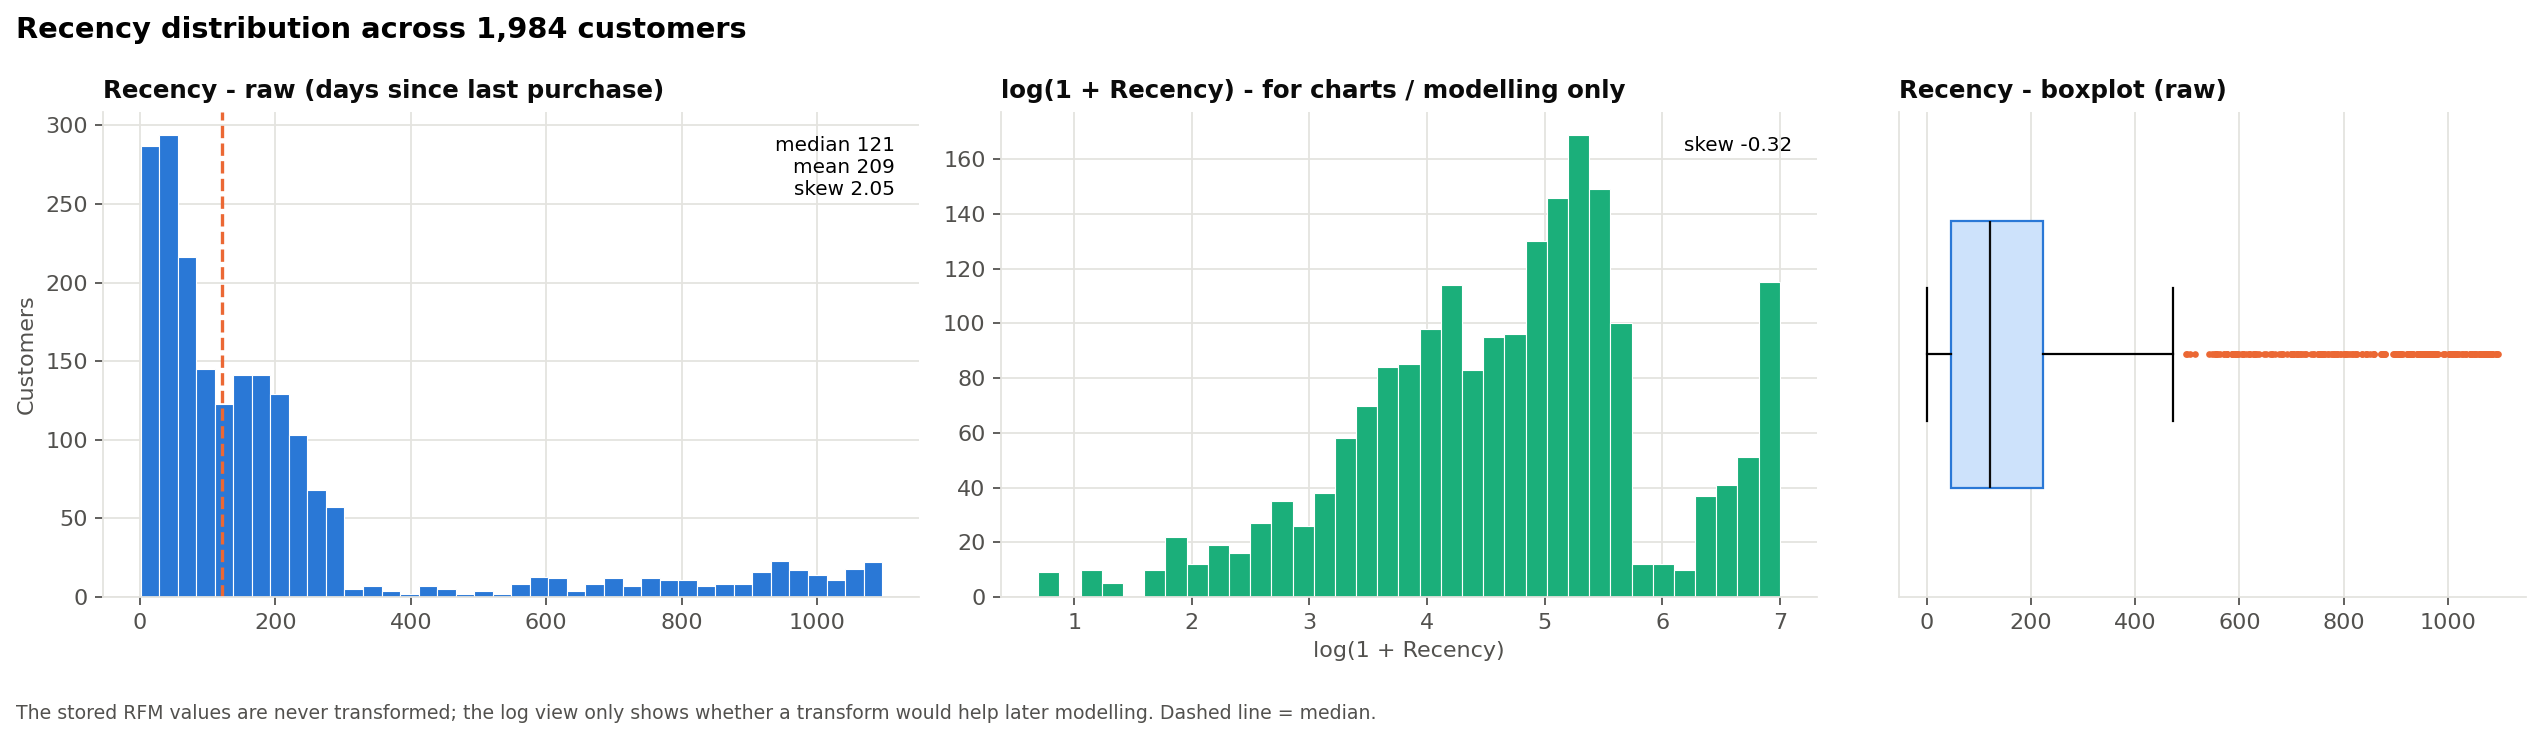

In [9]:
Image(str(FIG / "rfm_recency_distribution.png"))

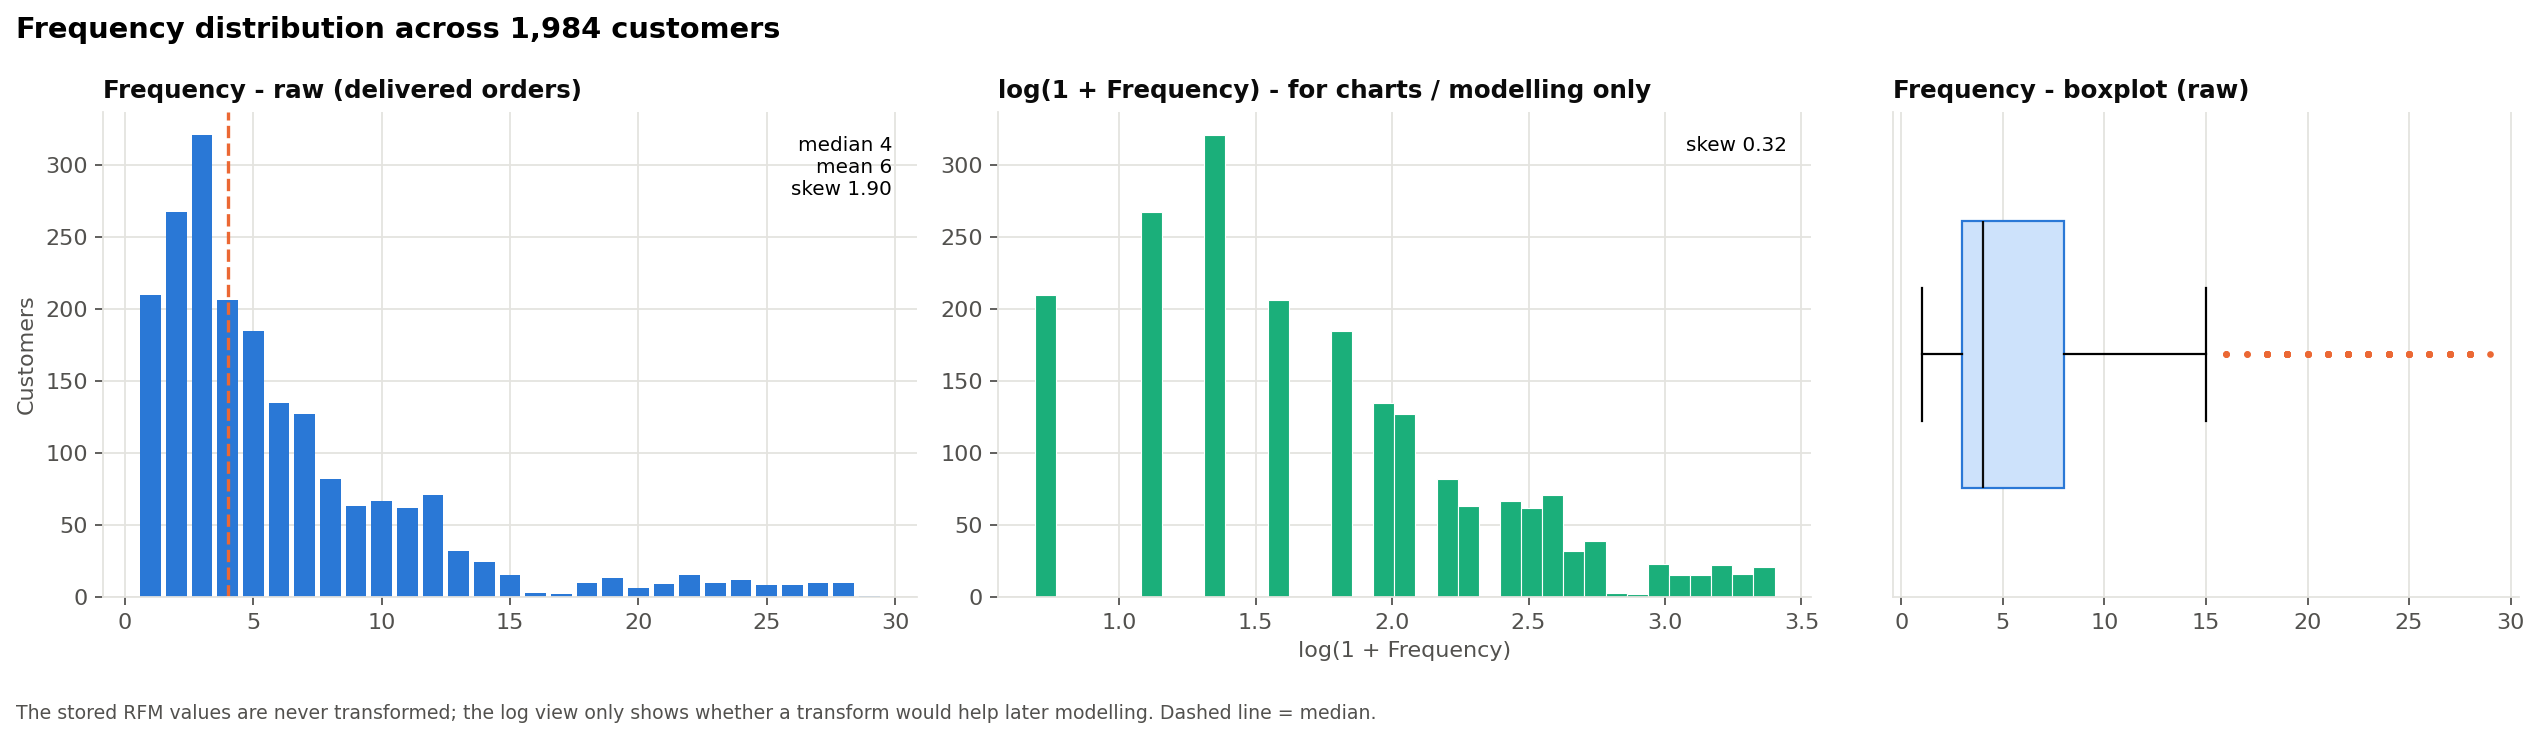

In [10]:
Image(str(FIG / "rfm_frequency_distribution.png"))

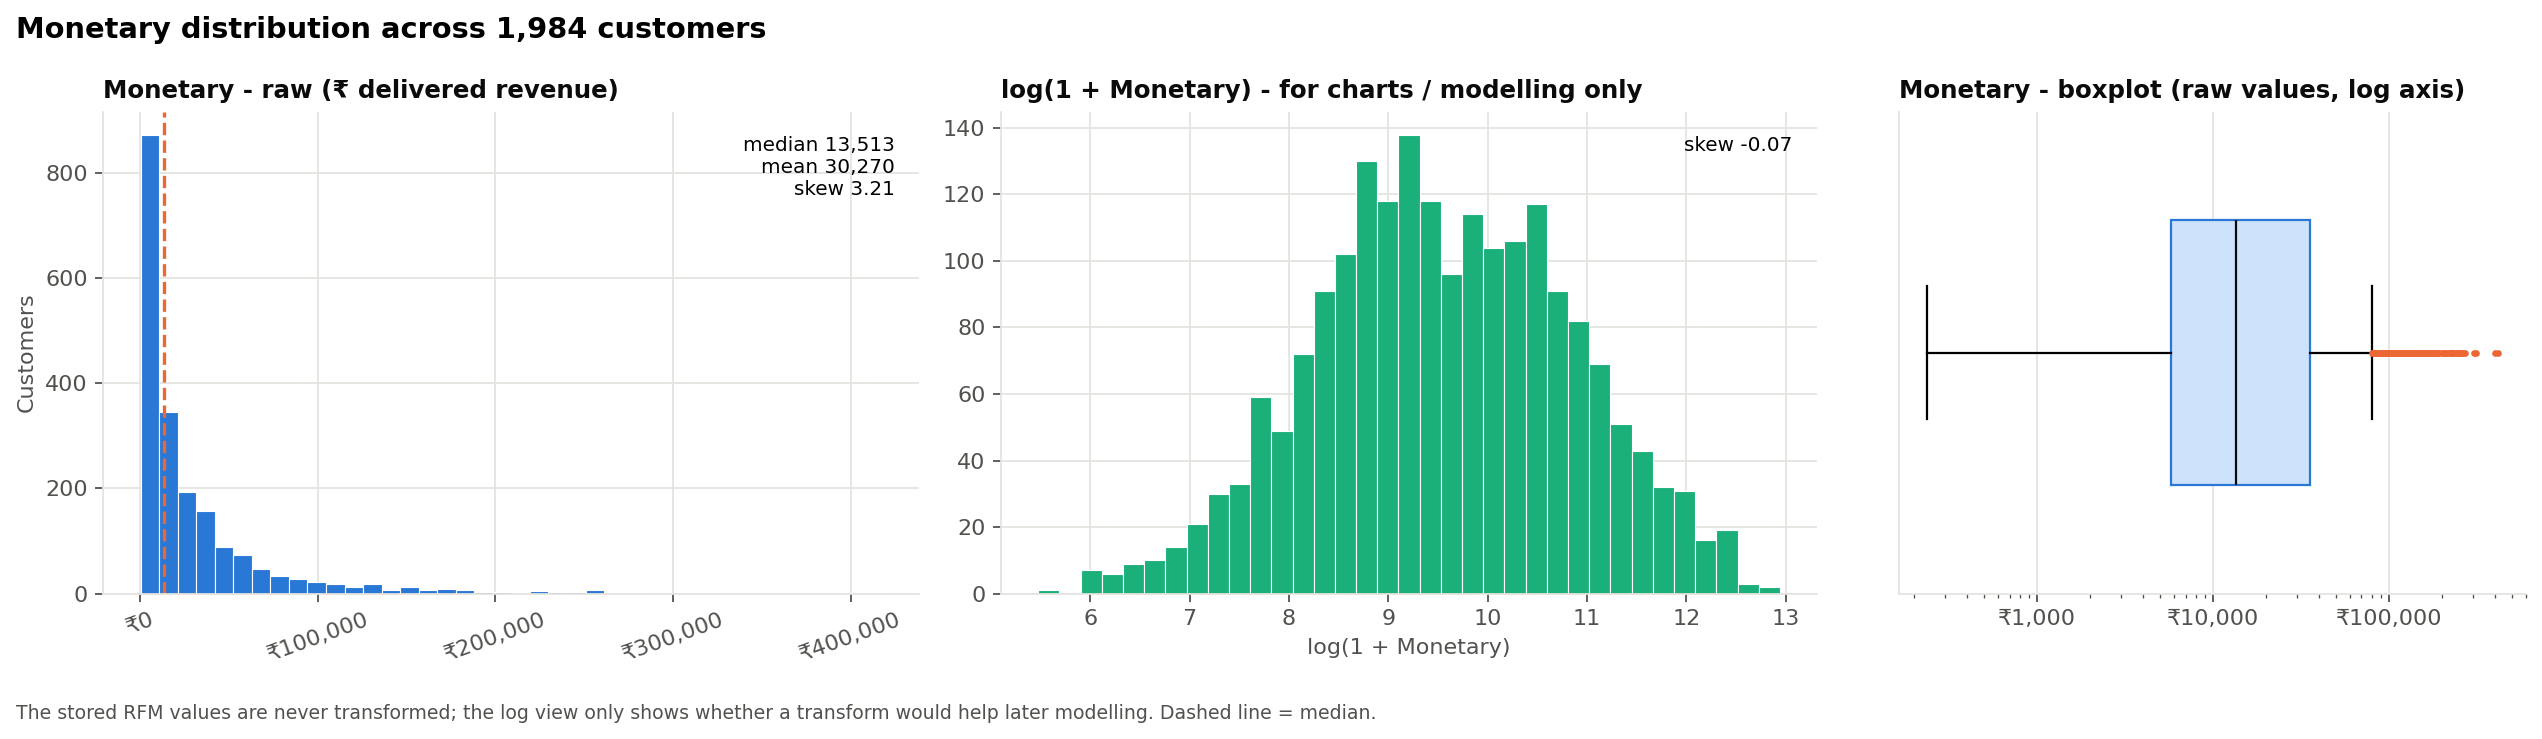

In [11]:
Image(str(FIG / "rfm_monetary_distribution.png"))

In [12]:
R['describe']['log_check']

,Metric,Skewness_raw,Skewness_log1p,Recommendation
0,Recency,2.05,-0.32,log1p reduces skew - use for charts and as model input in Step 6
1,Frequency,1.90,0.32,log1p reduces skew - use for charts and as model input in Step 6
2,Monetary,3.21,-0.07,log1p reduces skew - use for charts and as model input in Step 6


**Observation.**
- **Recency:** median 121 days (mean 209). The long right tail reaches 1,096 days, from customers who stopped buying in early 2023.
- **Frequency:** median 4 orders (mean 6.2, maximum 29). **89.4% are repeat customers**, and 10.6% bought only once.
- **Monetary:** median ₹13,513, mean ₹30,270. The mean is 2.2 times the median, and the range is ₹238 to ₹4.18 L.
- 42.5% of customers bought in the last 90 days. **34.9% have not bought for more than 180 days.**
- All three measures are right-skewed (skewness 1.9 to 3.2). `log(1 + x)` brings them to near-symmetric (−0.3 to 0.3).

**Interpretation.**
- Averages overstate the "typical" customer, so medians are reported alongside.
- The log transform is **recommended for K-Means in Step 6**, because distance-based clustering is distorted by long tails. The stored RFM values remain untransformed.

## 9. RFM Scoring

In [13]:
R['qcut_check']

,Metric,Unique_Values,Quintile_Edges,Duplicate_Edges,Plain_qcut_OK,Largest_Tie_Group_%,Agreement_with_tie_aware_%
0,Recency,513,"1, 38, 83, 162, 254, 1,096",0,True,1.30,98.80
1,Frequency,29,"1, 2, 3, 6, 9, 29",0,True,16.20,93.20
2,Monetary,1984,"238, 4,707, 9,522, 19,911, 43,278, 417,800",0,True,0.10,99.90


**Checking the quintile method before using it.**
- Frequency has only 29 distinct values, and 16% of customers share the most common one, so quintile edges could collide.
- On this data the edges are **unique for all three measures**, so plain `pd.qcut(q=5)` is used. qcut keeps identical values in the same score.
- `robust_quantile_score()` falls back to a tie-aware percentile rank (score = ceil(5 × average percentile rank)) if a future dataset produces duplicate edges.
- The two methods agree for 93-99.9% of customers here, so the choice does not change the conclusions.

In [14]:
R['score_bins']

,Metric,Score,Customers,Min_Value,Max_Value,Median_Value,Share_of_Customers,Method
0,Recency,1,393,255.00,"1,096.00",691.00,0.20,pd.qcut(q=5) quintiles
1,Recency,2,398,163.00,254.00,201.00,0.20,pd.qcut(q=5) quintiles
2,Recency,3,396,84.00,162.00,121.00,0.20,pd.qcut(q=5) quintiles
3,Recency,4,388,39.00,83.00,57.00,0.20,pd.qcut(q=5) quintiles
4,Recency,5,409,1.00,38.00,21.00,0.21,pd.qcut(q=5) quintiles
5,Frequency,1,477,1.00,2.00,2.00,0.24,pd.qcut(q=5) quintiles
6,Frequency,2,321,3.00,3.00,3.00,0.16,pd.qcut(q=5) quintiles
7,Frequency,3,526,4.00,6.00,5.00,0.27,pd.qcut(q=5) quintiles
8,Frequency,4,272,7.00,9.00,8.00,0.14,pd.qcut(q=5) quintiles
9,Frequency,5,388,10.00,29.00,12.00,0.20,pd.qcut(q=5) quintiles


In [15]:
seg[['Customer_ID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Cell', 'RFM_Score', 'FM_Score']].head(10)

,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Cell,RFM_Score,FM_Score
0,CUST-0001,10,5,"10,990.15",5,3,3,533,11,3.00
1,CUST-0002,2,11,"43,213.65",5,5,4,554,14,4.50
2,CUST-0003,146,6,"22,484.85",3,3,4,334,10,3.50
3,CUST-0004,90,3,"36,127.40",3,2,4,324,9,3.00
4,CUST-0005,62,11,"38,964.45",4,5,4,454,13,4.50
5,CUST-0006,77,11,"46,920.15",4,5,5,455,14,5.00
6,CUST-0007,29,6,"14,739.80",5,3,3,533,11,3.00
7,CUST-0008,74,11,"87,405.80",4,5,5,455,14,5.00
8,CUST-0009,1015,1,"5,585.20",1,1,2,112,4,1.50
9,CUST-0010,121,3,"4,174.10",3,2,1,321,6,1.50


| Field | Formula | Why |
|---|---|---|
| R_Score | quintile of Recency, **reversed** (1-38 days = 5) | Recent = better |
| F_Score / M_Score | quintile of Frequency / Monetary (higher = 5) | More = better |
| RFM_Cell | R, F and M digits joined, e.g. "545" | Readable label |
| RFM_Score | R + F + M (3-15) | **Equal weights.** No evidence in the data justifies weighting one dimension more than another. |
| FM_Score | (F + M) / 2 | Used by the segment rules. F and M are strongly correlated (ρ = 0.84, below), so averaging avoids double-counting. |

F_Score bands are unequal in size: all 321 customers with exactly 3 orders share F = 2. This is the honest result of tied values.

In [16]:
seg[['Recency', 'Frequency', 'Monetary']].corr('spearman')

,Recency,Frequency,Monetary
Recency,1.00,-0.38,-0.34
Frequency,-0.38,1.00,0.84
Monetary,-0.34,0.84,1.00


## 10. Customer Value Segments
### 10.1 Segment rules (rule-based, transparent, exhaustive)

In [17]:
R['segment_rules']

,Segment,RFM Characteristics (rule),Business Meaning,Value-Activity Group
0,Champions,R 4-5 and FM >= 4.5,"Bought recently, buy often and spend the most",Active high value
1,Loyal Customers,R 3-5 and FM 3.5-4 (or R 3 and FM >= 4.5),"Regular, valuable buyers; strong relationship",Active high value
2,Potential Loyalists,R 4-5 and FM 2.5-3,Recent buyers with average frequency and spend,Developing
3,Recent Customers,R 5 and FM < 2.5,Bought very recently but only a little so far,Developing
4,Promising,R 4 and FM < 2.5,"Fairly recent, low frequency and spend",Developing
5,Needs Attention,R 3 and FM 2.5-3,Average customers whose recency is slipping,Slipping
6,About to Sleep,R 3 and FM < 2.5,Below-average value and going quiet,Slipping
7,Can't Lose Them,R 1-2 and FM >= 4.5,Were among the best customers; have not bought for a long time,Slipping
8,At Risk,R 1-2 and FM 3-4,"Valuable in the past, now inactive",Slipping
9,Hibernating,R 2 and FM < 3,Low value and long inactive,Inactive


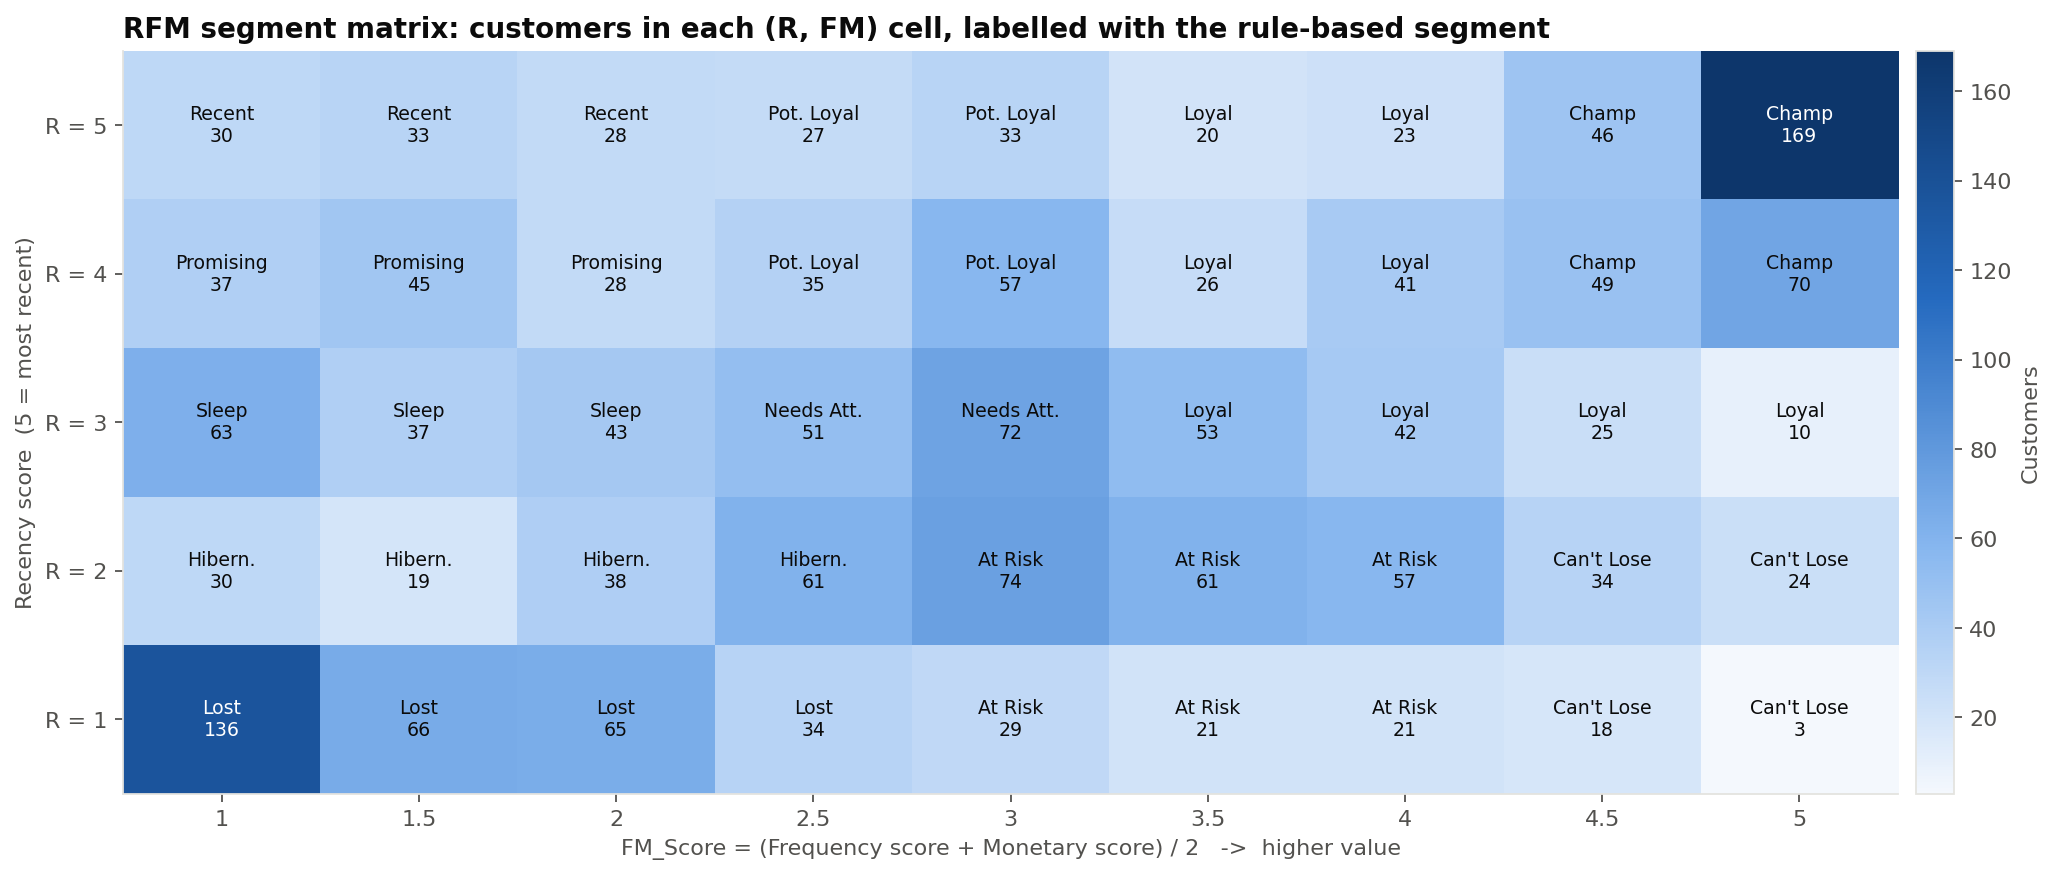

In [18]:
Image(str(FIG / "rfm_segment_matrix.png"))

- The rules are evaluated top-down on R_Score and FM_Score.
- The grid covers every (R, FM) combination, so every customer gets **exactly one** segment. This is verified in Section 16.
- For readability, the 11 segments are grouped into four **value-activity groups**: Active high value, Developing, Slipping and Inactive.

**All 11 conventional labels are supported by the data.** The smallest segment, Can't Lose Them, has 79 customers (4.0%), which is large enough to act on.

These are **analytical rules, not machine-learning clusters**. K-Means in Step 6 will test whether the data's natural groupings agree with them.

In [19]:
seg['RFM_Segment'].value_counts().reindex(rfm.SEGMENT_ORDER).to_frame('Customers')

,Customers
RFM_Segment,
Champions,334
Loyal Customers,240
Potential Loyalists,152
Recent Customers,91
Promising,110
Needs Attention,123
About to Sleep,143
Can't Lose Them,79
At Risk,263


## 11. Segment-Level Business Analysis

In [20]:
R['segment_summary']

,RFM_Segment,Value_Activity_Group,Customer_Count,Customer_%,Total_Revenue,Revenue_%,Average_Revenue,Average_Recency,Median_Recency,Average_Frequency,Average_Monetary,Median_Monetary,Average_Order_Value,Profit_Margin,Revenue_to_Customer_Ratio,Average_R_Score,Average_F_Score,Average_M_Score
0,Champions,Active high value,334,16.84,"32,330,090.40",53.83,"96,796.68",32.59,29.50,15.43,"96,796.68","74,370.82","6,275.25",0.22,3.20,4.64,4.90,4.81
1,Loyal Customers,Active high value,240,12.10,"8,578,897.60",14.29,"35,745.41",91.19,91.50,7.18,"35,745.41","29,369.20","4,976.16",0.23,1.18,3.64,3.72,4.05
2,Potential Loyalists,Developing,152,7.66,"2,191,483.35",3.65,"14,417.65",46.63,46.00,4.20,"14,417.65","12,159.15","3,434.93",0.25,0.48,4.39,2.72,2.87
3,Recent Customers,Developing,91,4.59,"488,562.60",0.81,"5,368.82",17.79,16.00,2.23,"5,368.82","5,052.45","2,406.71",0.35,0.18,5.00,1.37,1.60
4,Promising,Developing,110,5.54,"562,907.70",0.94,"5,117.34",59.38,58.00,2.20,"5,117.34","4,541.55","2,326.07",0.34,0.17,4.00,1.40,1.52
5,Needs Attention,Slipping,123,6.20,"1,553,870.95",2.59,"12,633.10",120.65,120.00,4.47,"12,633.10","10,775.30","2,825.22",0.29,0.42,3.00,2.81,2.77
6,About to Sleep,Slipping,143,7.21,"605,262.25",1.01,"4,232.60",115.36,111.00,2.12,"4,232.60","3,613.70","1,997.57",0.31,0.14,3.00,1.46,1.40
7,Can't Lose Them,Slipping,79,3.98,"4,285,311.30",7.13,"54,244.45",228.29,226.00,9.80,"54,244.45","51,946.25","5,536.58",0.20,1.79,1.73,4.70,4.65
8,At Risk,Slipping,263,13.26,"6,763,493.30",11.26,"25,716.71",259.32,218.00,5.90,"25,716.71","22,178.50","4,357.92",0.24,0.85,1.73,3.27,3.63
9,Hibernating,Inactive,148,7.46,"975,827.80",1.62,"6,593.43",199.01,195.00,3.07,"6,593.43","6,103.65","2,149.40",0.34,0.22,2.00,2.05,1.82


In [21]:
R['group_summary']

,Value_Activity_Group,Customers,Revenue,Average_Recency,Average_Frequency,Average_Monetary,Customer_%,Revenue_%
0,Active high value,574,"40,908,988.00",57.09,11.98,"71,270.01",28.93,68.12
1,Developing,353,"3,242,953.65",43.17,3.07,"9,186.84",17.79,5.40
2,Slipping,608,"13,207,937.80",193.37,5.23,"21,723.58",30.64,21.99
3,Inactive,449,"2,696,689.70",556.01,2.39,"6,005.99",22.63,4.49


In [22]:
R['segment_profile']

,RFM_Segment,Customers,Share_Existing_Before_2023_%,Median_Age,Median_Tenure_Days,Avg_Categories_Bought,Avg_Discount_%,Return_Lines_per_Customer,Top_Region,Top_Region_Share_%
0,Champions,334,64.37,36.00,957.50,5.30,10.59,1.35,West,24.85
1,Loyal Customers,240,48.75,34.00,845.50,4.30,12.44,0.60,South,30.42
2,Potential Loyalists,152,32.24,29.50,651.50,3.22,14.86,0.25,South,30.26
3,Recent Customers,91,6.59,30.00,77.00,2.12,15.10,0.16,West,24.18
4,Promising,110,10.00,27.00,122.50,2.15,16.10,0.25,South,26.36
5,Needs Attention,123,33.33,30.00,746.00,3.54,14.67,0.39,West,26.02
6,About to Sleep,143,18.18,29.00,276.00,2.06,18.30,0.21,South,27.27
7,Can't Lose Them,79,40.51,35.00,876.00,4.91,12.82,0.58,North,35.44
8,At Risk,263,41.83,33.00,791.00,3.89,12.38,0.59,South,28.90
9,Hibernating,148,25.00,29.00,590.50,2.61,15.31,0.36,South,30.41


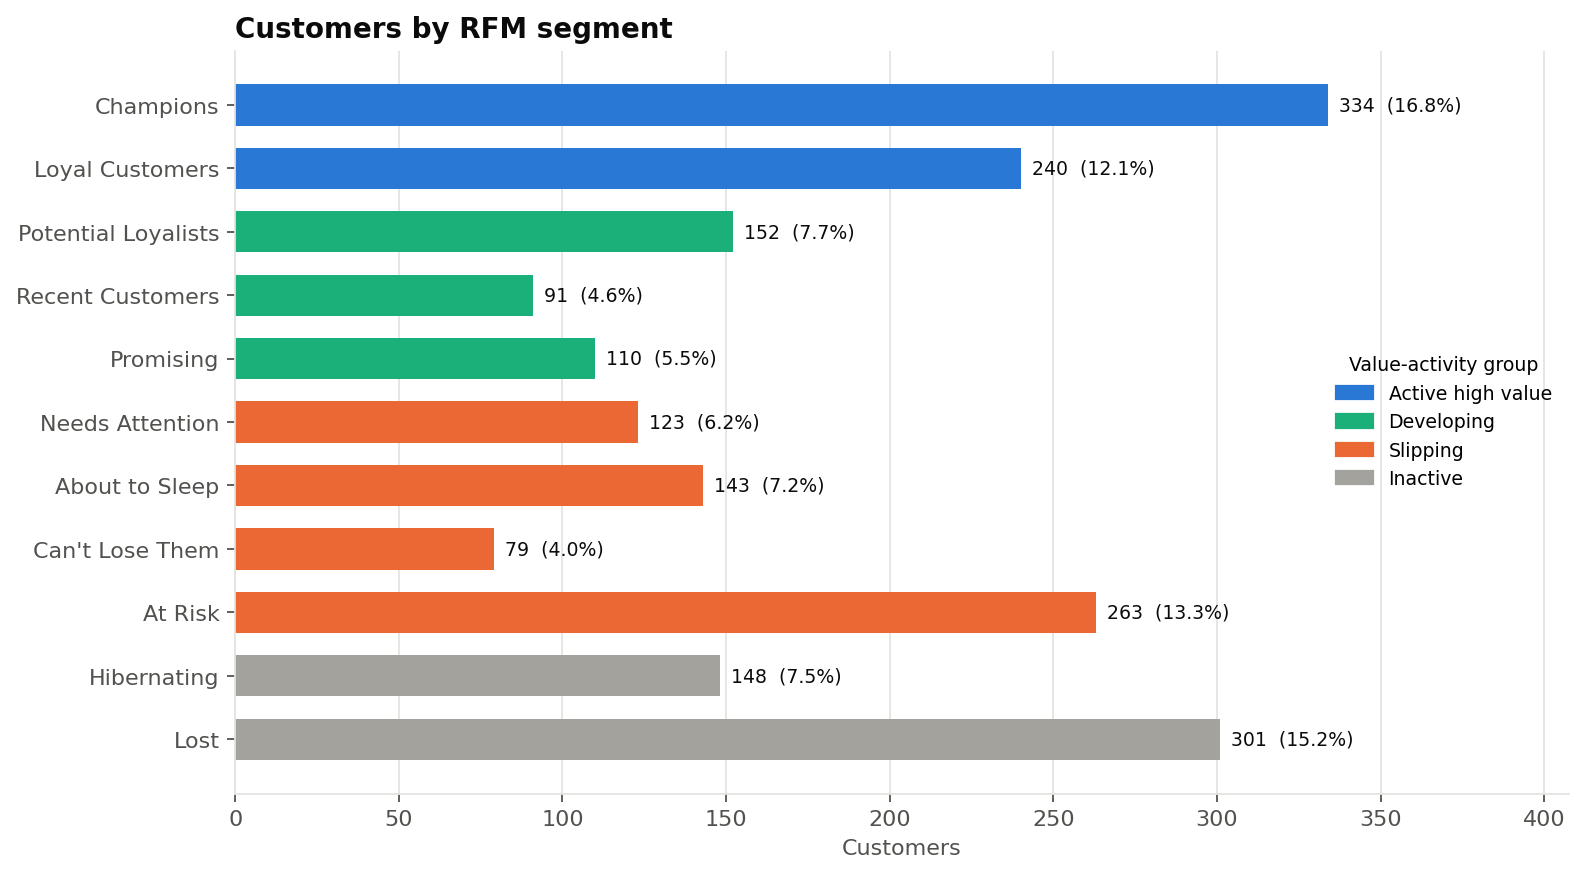

In [23]:
Image(str(FIG / "rfm_segment_distribution.png"))

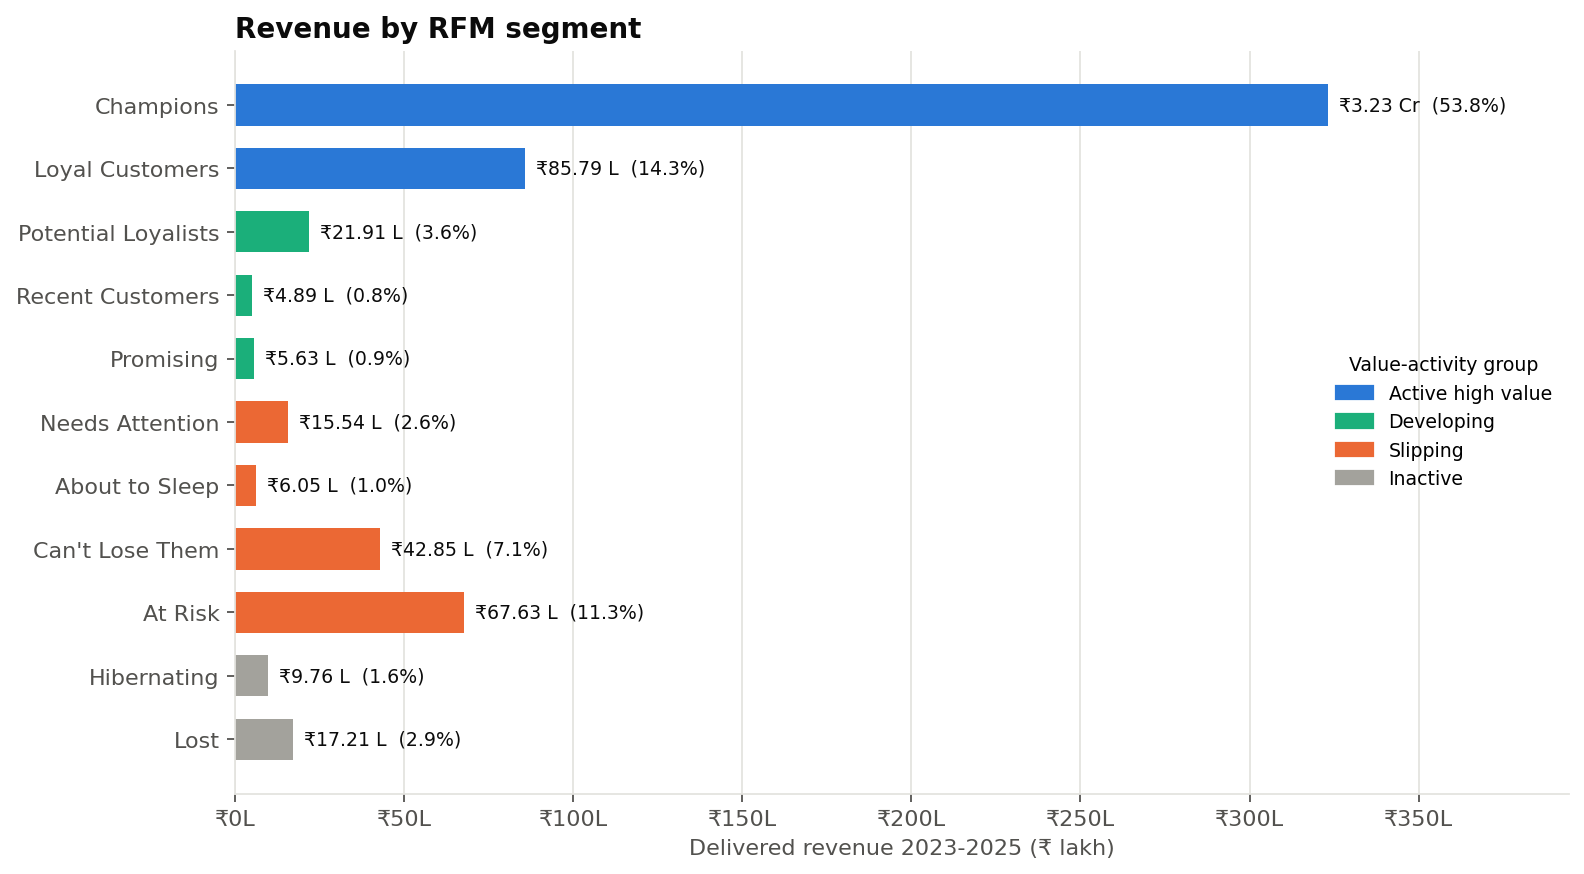

In [24]:
Image(str(FIG / "rfm_revenue_by_segment.png"))

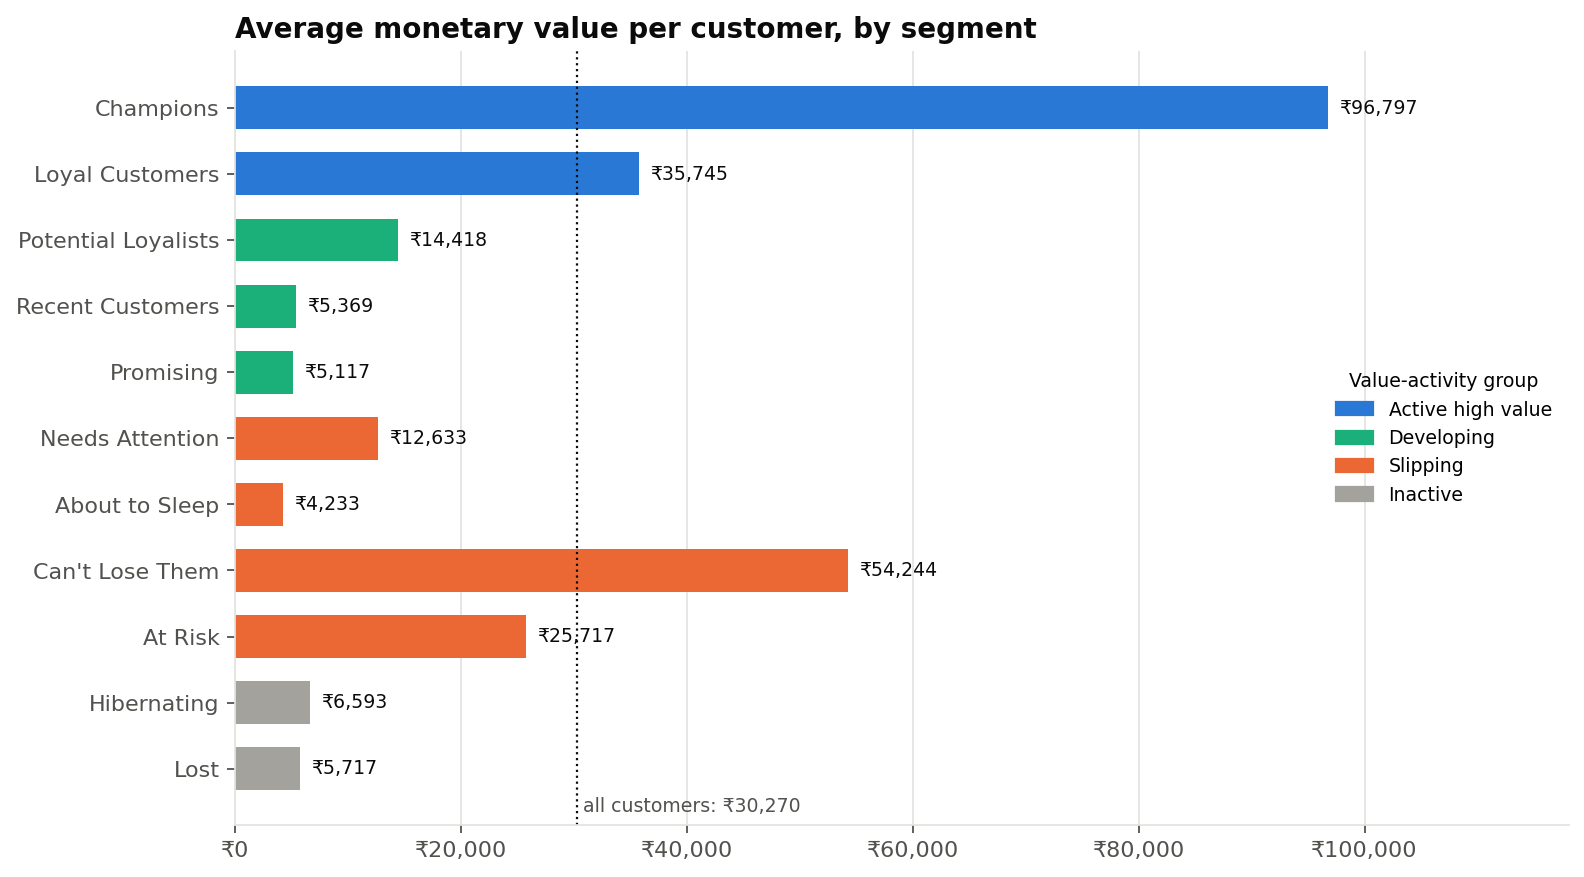

In [25]:
Image(str(FIG / "rfm_segment_monetary.png"))

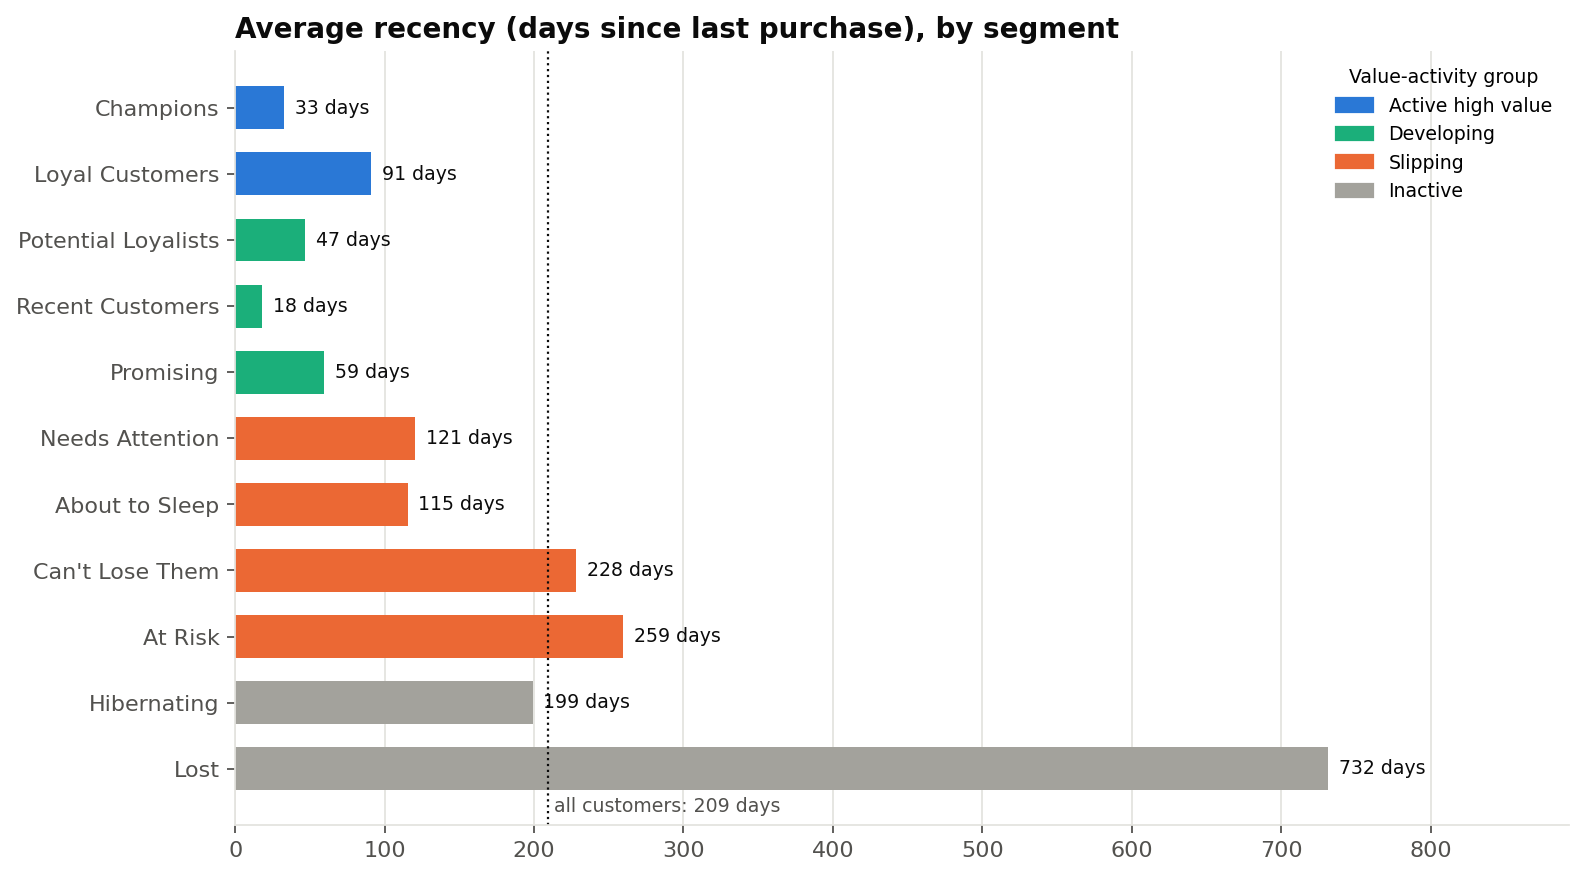

In [26]:
Image(str(FIG / "rfm_segment_recency.png"))

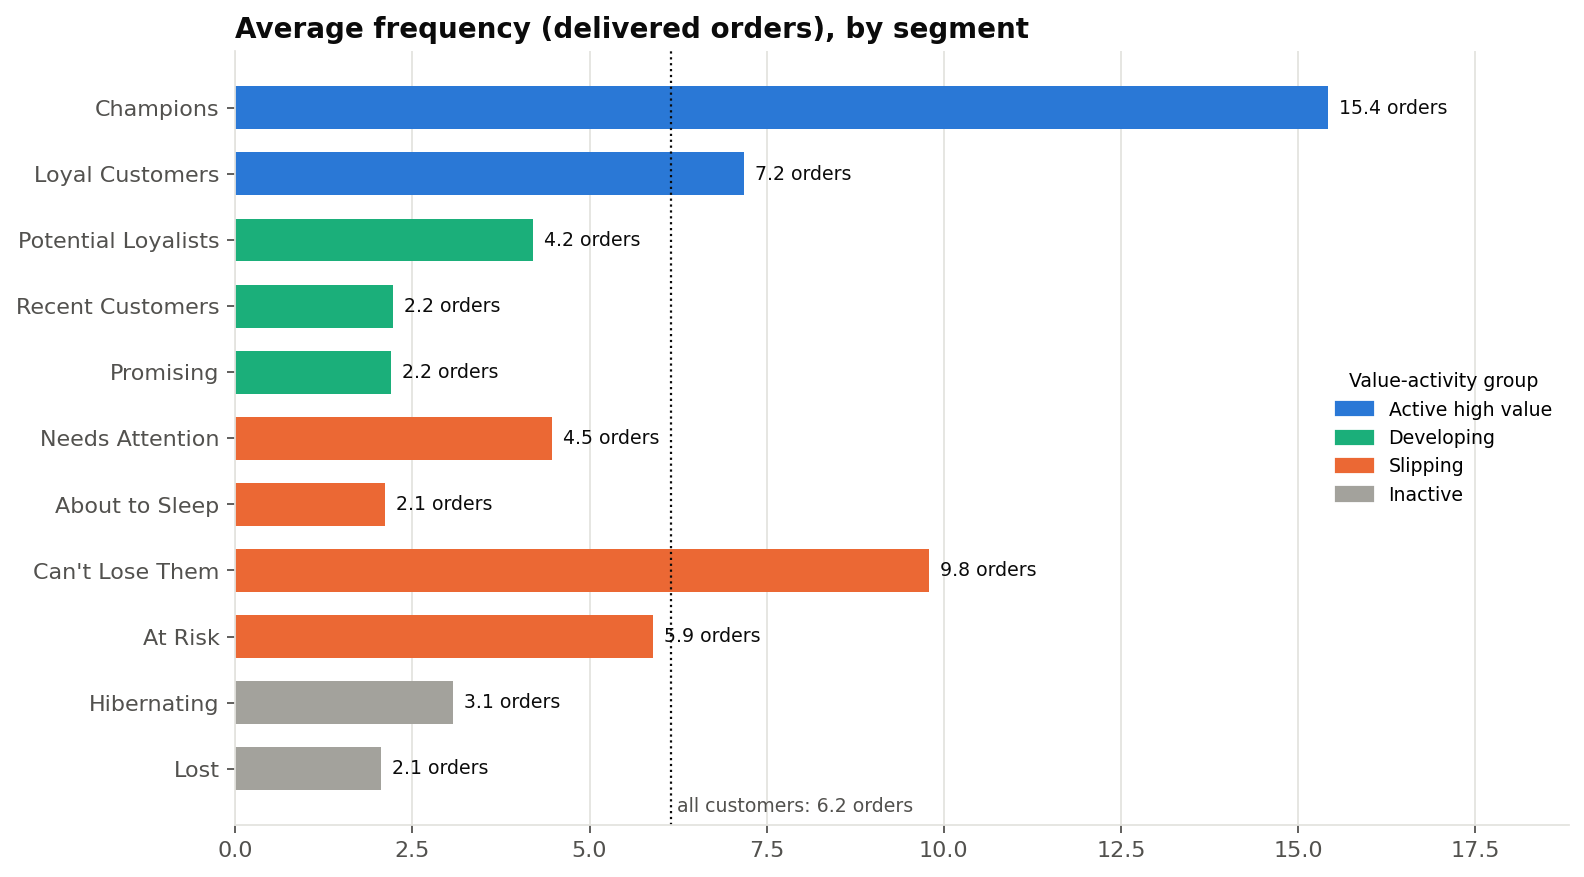

In [27]:
Image(str(FIG / "rfm_segment_frequency.png"))

**Observation.**
- **Champions** are the largest segment: **334 customers (16.8%) generating ₹3.23 Cr (53.8% of revenue)**. They average 15.4 orders, ₹96,797 each, and last bought 33 days ago on average.
- **Loyal Customers** (240) add 14.3% of revenue. Together, the "Active high value" group is **28.9% of customers and 68.1% of revenue**.
- **At Risk** (263 customers, ₹67.63 L, 11.3%) and **Can't Lose Them** (79 customers, ₹42.85 L, 7.1%) were valuable but have not bought for about 228-259 days on average. Can't Lose Them average ₹54,244 each, the second-highest of any segment.
- **Lost** (301) and **Hibernating** (148) together are 22.6% of customers but only 4.5% of revenue.
- **Profile (context only):**
  - 64% of Champions were already customers before 2023, while 93% of Recent Customers were acquired during 2023-25.
  - Champions receive the *lowest* average discount (10.6%), and About to Sleep the highest (18.3%).
  - Median age rises from 27-30 in the low-value segments to 36 among Champions.

**Interpretation.**
- Value and loyalty build over time: the best customers are long-standing, buy across about 5 categories, and do not need deep discounts.
- Heavily discounted customers are the least engaged. This is consistent with Step 4's finding that discounts erode margin without lifting volume. It is an association, not proof that discounts cause disengagement.

## 12. Revenue Contribution Analysis

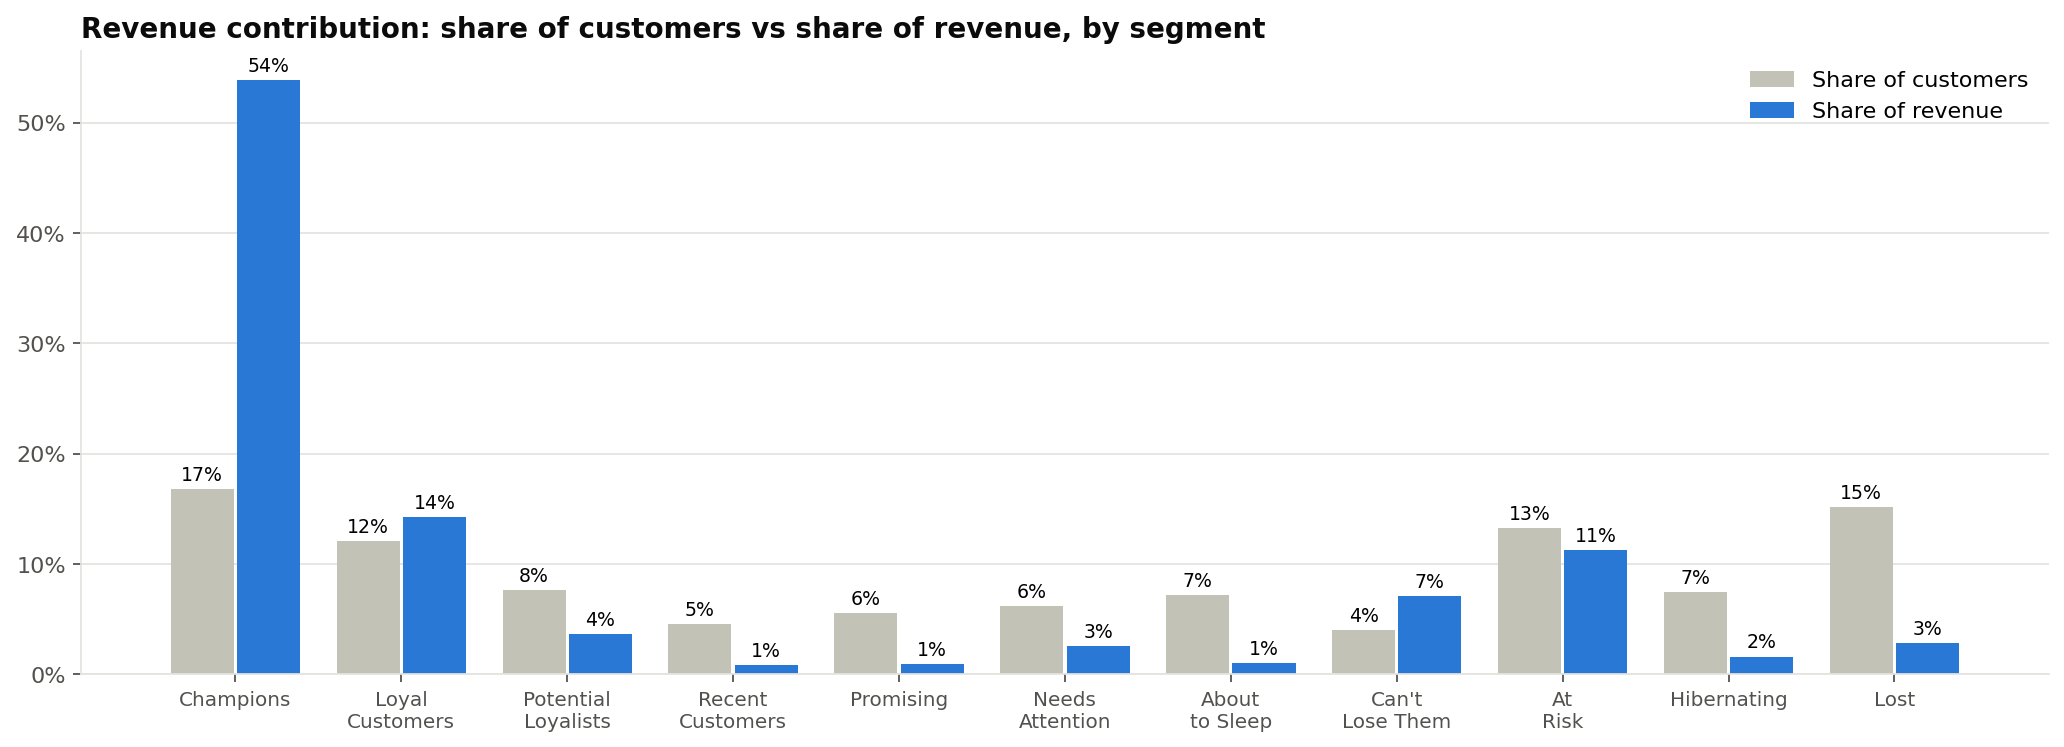

In [28]:
Image(str(FIG / "rfm_revenue_contribution.png"))

In [29]:
s = R["segment_summary"][["RFM_Segment", "Customer_%", "Revenue_%", "Revenue_to_Customer_Ratio"]]
s.sort_values("Revenue_to_Customer_Ratio", ascending=False)

,RFM_Segment,Customer_%,Revenue_%,Revenue_to_Customer_Ratio
0,Champions,16.84,53.83,3.20
7,Can't Lose Them,3.98,7.13,1.79
1,Loyal Customers,12.10,14.29,1.18
8,At Risk,13.26,11.26,0.85
2,Potential Loyalists,7.66,3.65,0.48
5,Needs Attention,6.20,2.59,0.42
9,Hibernating,7.46,1.62,0.22
10,Lost,15.17,2.87,0.19
3,Recent Customers,4.59,0.81,0.18
4,Promising,5.54,0.94,0.17


**Observation.** Three segments contribute **more revenue than their share of customers**:
- Champions: 3.2 times their customer share.
- Can't Lose Them: 1.8 times.
- Loyal Customers: 1.2 times.

Every other segment contributes less. The Lost segment is 15.2% of customers but only 2.9% of revenue.

**Interpretation.** Retention spending should follow the revenue-to-customer ratio: protect the three over-contributing segments first, and use low-cost automation for the rest.

## 13. Customer Concentration Analysis

In [30]:
display(R['concentration']['concentration']); R['concentration']['concentration_stats']

,Customer_Group,Customers,Revenue,Revenue_Share_%,Min_Monetary_in_Group
0,Top 1%,20,"5,432,938.75",9.05,"229,505.40"
1,Top 5%,100,"18,046,041.25",30.05,"118,032.05"
2,Top 10%,199,"27,333,640.50",45.51,"75,012.80"
3,Top 20%,397,"38,636,236.25",64.33,"43,321.85"
4,Top 50%,992,"54,024,698.30",89.96,"13,520.45"


,Measure,Value
0,Scored customers,"1,984.00"
1,"Gini coefficient (0 = equal, 1 = one customer has all)",0.61
2,Customers needed for 50% of revenue,238.00
3,Share of customers needed for 50% of revenue (%),12.00
4,Customers needed for 80% of revenue,676.00
5,Share of customers needed for 80% of revenue (%),34.10
6,Top 20% share of revenue (%),64.30


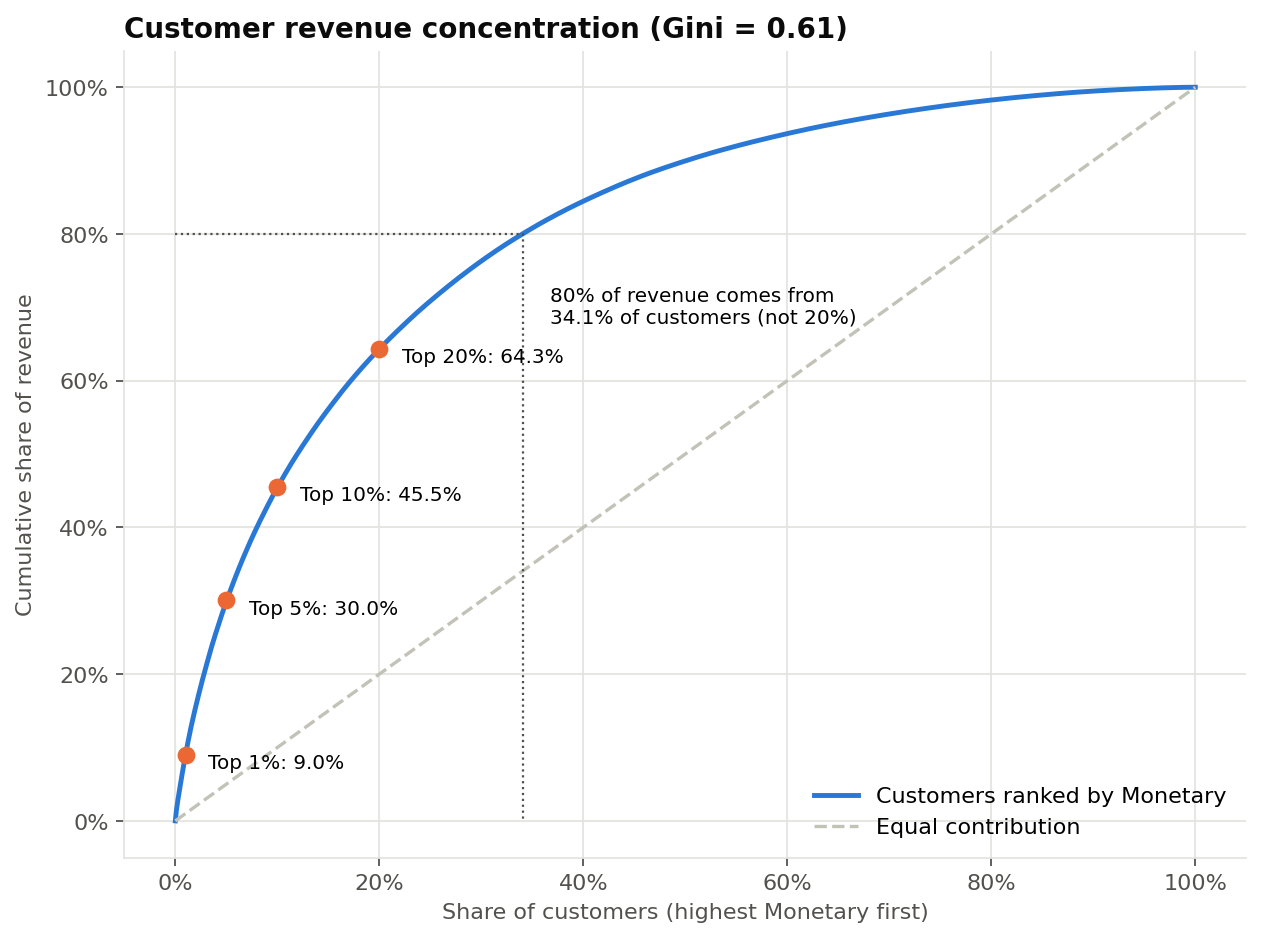

In [31]:
Image(str(FIG / "rfm_revenue_concentration.png"))

**Observation.**
- The top 1% of customers (20 people) generate **9.0%** of revenue, the top 5% **30.0%**, the top 10% **45.5%** and the top 20% **64.3%**. The Gini coefficient is 0.61.
- Half of all revenue comes from just **12.0%** of customers.
- 80% of revenue comes from **34.1%** of customers.

**Is this a Pareto (80/20) rule?** No. Revenue is clearly and disproportionately concentrated, but a literal 80/20 split would need the top 20% to produce 80%, and here they produce 64%. The honest description is *strong concentration, weaker than 80/20*. The 2,000-customer base is large enough for these percentile shares to be meaningful.

## 14. RFM Visualization
### 14.1 High-value customer lists (by Customer_ID only)

In [32]:
R['high_value']['top_monetary'].head(10)

,Customer_ID,Region,Recency,Frequency,Monetary,Average_Order_Value,R_Score,F_Score,M_Score,RFM_Cell,RFM_Segment
1119,CUST-1128,South,13,27,"417,800.45","15,474.09",5,5,5,555,Champions
1710,CUST-1724,South,30,28,"400,151.70","14,291.13",5,5,5,555,Champions
664,CUST-0669,North,9,16,"314,818.65","19,676.17",5,5,5,555,Champions
901,CUST-0908,Central,29,26,"307,090.05","11,811.16",5,5,5,555,Champions
1162,CUST-1172,South,25,25,"272,866.60","10,914.66",5,5,5,555,Champions
933,CUST-0941,North,13,27,"263,670.35","9,765.57",5,5,5,555,Champions
1952,CUST-1969,North,37,25,"261,877.00","10,475.08",5,5,5,555,Champions
1036,CUST-1044,North,17,29,"258,231.30","8,904.53",5,5,5,555,Champions
1404,CUST-1416,West,26,22,"255,399.20","11,609.05",5,5,5,555,Champions
1475,CUST-1489,South,15,28,"255,128.00","9,111.71",5,5,5,555,Champions


In [33]:
R['high_value']['top_frequency'].head(10)

,Customer_ID,Region,Recency,Frequency,Monetary,Average_Order_Value,R_Score,F_Score,M_Score,RFM_Cell,RFM_Segment
1036,CUST-1044,North,17,29,"258,231.30","8,904.53",5,5,5,555,Champions
1710,CUST-1724,South,30,28,"400,151.70","14,291.13",5,5,5,555,Champions
1475,CUST-1489,South,15,28,"255,128.00","9,111.71",5,5,5,555,Champions
1963,CUST-1980,East,15,28,"229,505.40","8,196.62",5,5,5,555,Champions
1513,CUST-1527,East,29,28,"223,486.50","7,981.66",5,5,5,555,Champions
469,CUST-0473,Central,25,28,"208,319.20","7,439.97",5,5,5,555,Champions
686,CUST-0691,West,4,28,"168,046.05","6,001.64",5,5,5,555,Champions
1238,CUST-1249,East,36,28,"151,511.80","5,411.14",5,5,5,555,Champions
1907,CUST-1923,North,8,28,"132,315.70","4,725.56",5,5,5,555,Champions
1596,CUST-1610,South,8,28,"119,368.85","4,263.17",5,5,5,555,Champions


In [34]:
R['high_value']['most_recent'].head(10)

,Customer_ID,Region,Recency,Frequency,Monetary,Average_Order_Value,R_Score,F_Score,M_Score,RFM_Cell,RFM_Segment
806,CUST-0813,West,1,21,"153,055.65","7,288.36",5,5,5,555,Champions
1878,CUST-1894,South,1,14,"130,400.15","9,314.30",5,5,5,555,Champions
1229,CUST-1240,South,1,21,"93,148.75","4,435.65",5,5,5,555,Champions
632,CUST-0636,East,1,10,"27,805.80","2,780.58",5,5,4,554,Champions
32,CUST-0033,West,1,7,"19,459.75","2,779.96",5,4,3,543,Loyal Customers
180,CUST-0182,West,1,4,"8,802.80","2,200.70",5,3,2,532,Potential Loyalists
516,CUST-0520,West,1,3,"7,393.85","2,464.62",5,2,2,522,Recent Customers
654,CUST-0658,South,1,2,"3,906.05","1,953.02",5,1,1,511,Recent Customers
1823,CUST-1838,South,1,4,"3,298.45",824.61,5,3,1,531,Recent Customers
1428,CUST-1441,Central,2,21,"150,476.80","7,165.56",5,5,5,555,Champions


### 14.2 High-value customers at risk
**Rule:** `M_Score ≥ 4` (top 40% by spend, Monetary ≥ ₹19,912) **and** `R_Score ≤ 2` (bottom 40% by recency, no purchase for ≥ 163 days).

The threshold comes from the same quintile scores used everywhere else, so it is not an arbitrary rupee or day cut-off.

In [35]:
display(R['high_value']['high_value_at_risk_rule']); R['high_value']['high_value_at_risk'].head(15)

,Item,Value
0,Rule,M_Score >= 4 (top 40% of customers by spend) AND R_Score <= 2 (bottom 40% by recency)
1,M_Score >= 4 means Monetary >=,"₹19,912"
2,R_Score <= 2 means Recency >=,163 days
3,Customers matching,229
4,Their total revenue,₹95.10 L
5,Share of all revenue,15.8%


,Customer_ID,Region,Recency,Frequency,Monetary,Average_Order_Value,R_Score,F_Score,M_Score,RFM_Cell,RFM_Segment
814,CUST-0821,North,183,12,"120,082.95","10,006.91",2,5,5,255,Can't Lose Them
755,CUST-0760,West,177,11,"118,651.00","10,786.45",2,5,5,255,Can't Lose Them
648,CUST-0652,North,216,7,"111,193.25","15,884.75",2,4,5,245,Can't Lose Them
1810,CUST-1825,North,225,7,"105,965.80","15,137.97",2,4,5,245,Can't Lose Them
848,CUST-0855,South,190,5,"104,118.40","20,823.68",2,3,5,235,At Risk
127,CUST-0129,North,213,3,"102,834.90","34,278.30",2,2,5,225,At Risk
637,CUST-0641,South,177,16,"98,247.75","6,140.48",2,5,5,255,Can't Lose Them
1722,CUST-1736,South,197,8,"92,051.55","11,506.44",2,4,5,245,Can't Lose Them
98,CUST-0100,East,230,3,"91,822.15","30,607.38",2,2,5,225,At Risk
958,CUST-0966,North,200,10,"90,605.95","9,060.59",2,5,5,255,Can't Lose Them


In [36]:
R['high_value']['high_value_at_risk']['RFM_Segment'].value_counts().to_frame('Customers')

,Customers
RFM_Segment,
At Risk,145
Can't Lose Them,79
Lost,5
Champions,0
Loyal Customers,0
Potential Loyalists,0
Recent Customers,0
Promising,0
Needs Attention,0


**Observation.**
- **229 customers** meet the rule. They generated **₹95.10 L (15.8% of all revenue)**, and their median time since last purchase is 226 days.
- By segment: 145 are At Risk, 79 are Can't Lose Them and 5 are Lost.

**Interpretation.** This is the most concrete win-back list in the project: an ID-based list for a reactivation campaign. Step 7 (CLV) will estimate how much future value is at stake.

### 14.3 Two-dimensional views

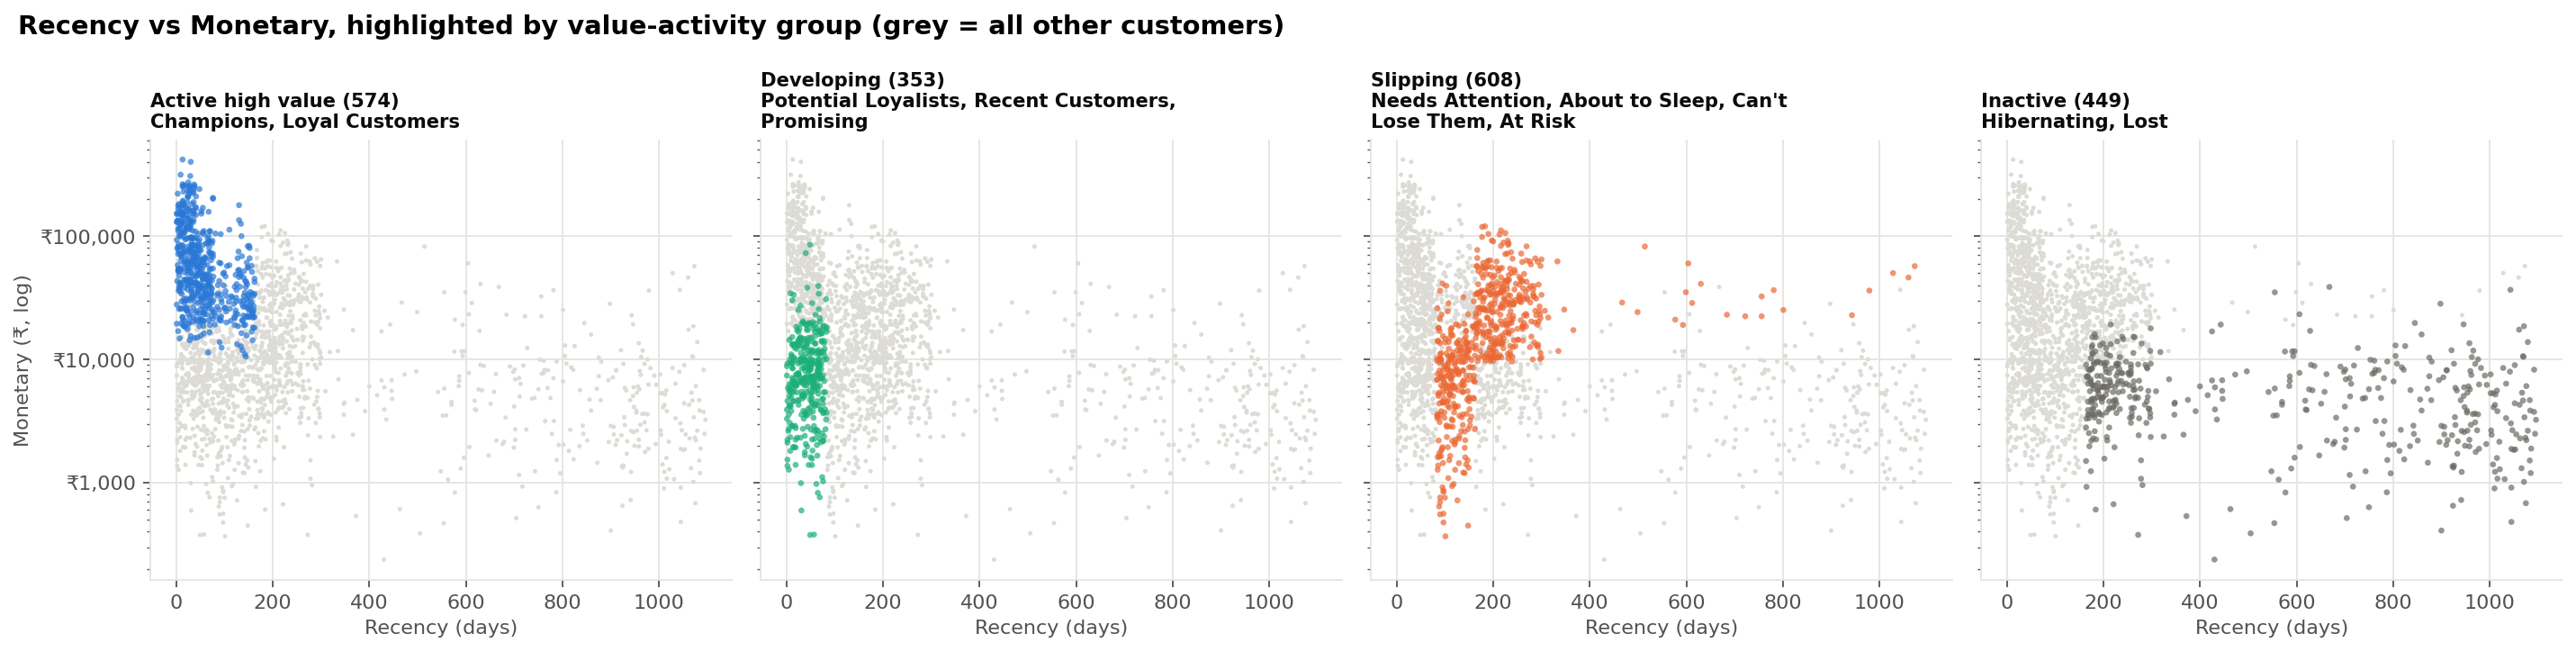

In [37]:
Image(str(FIG / "rfm_recency_vs_monetary.png"))

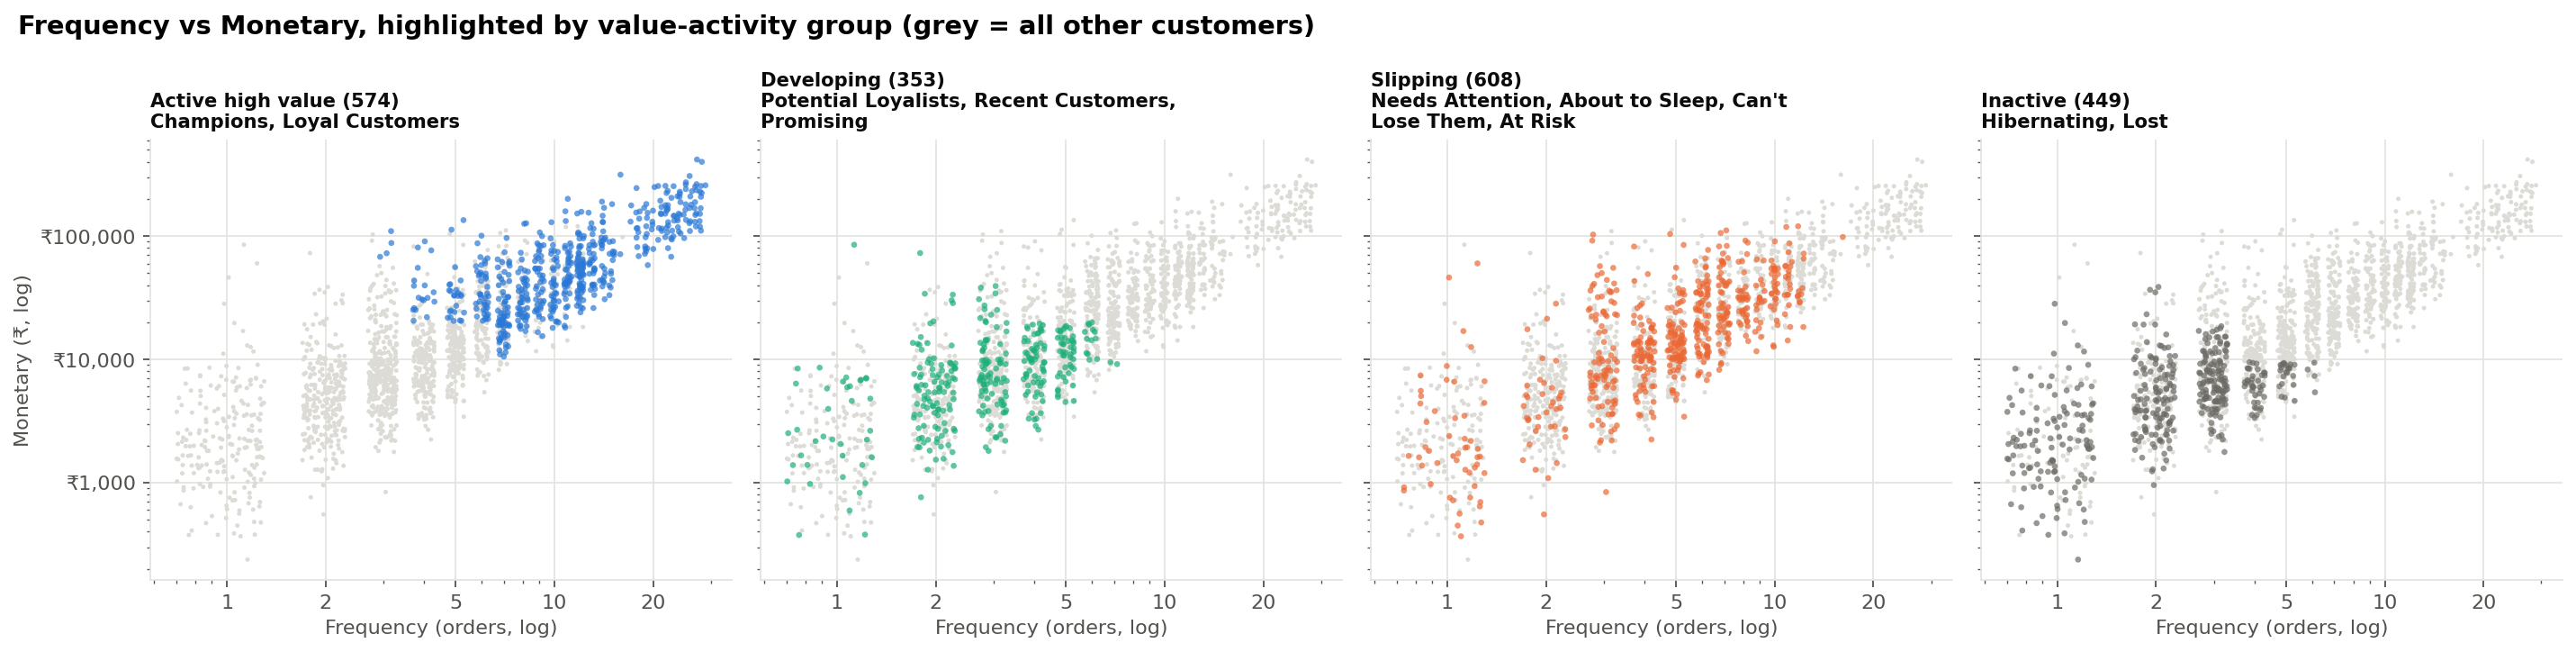

In [38]:
Image(str(FIG / "rfm_frequency_vs_monetary.png"))

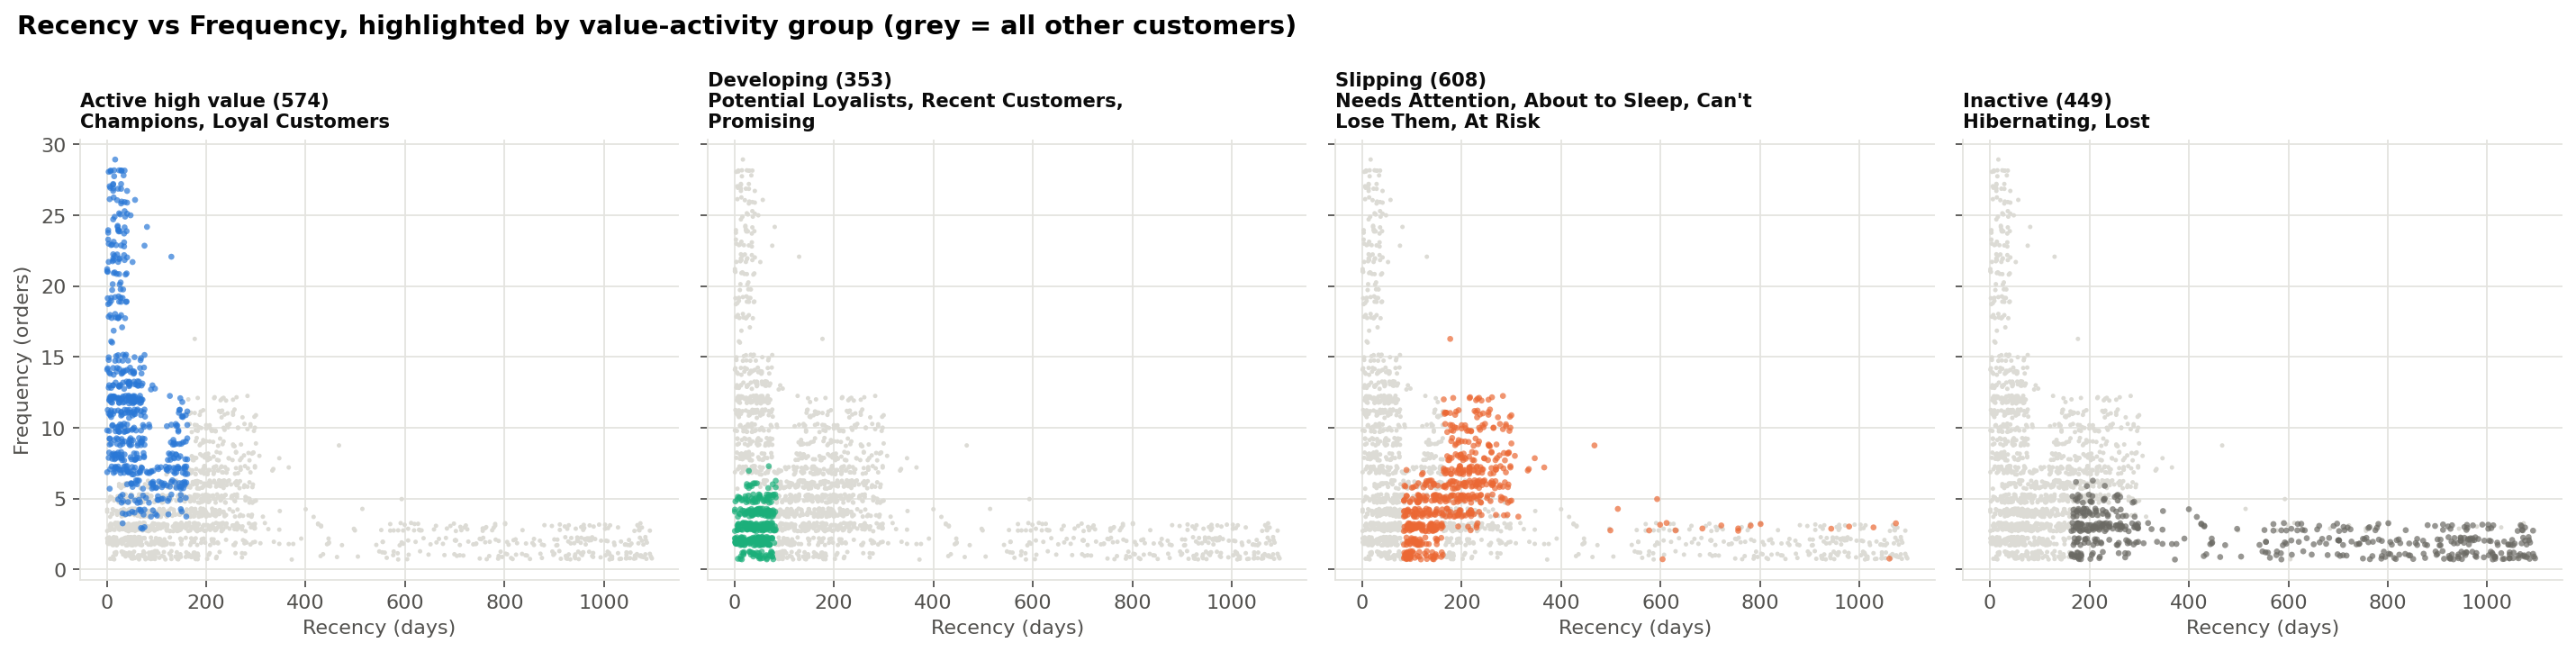

In [39]:
Image(str(FIG / "rfm_recency_vs_frequency.png"))

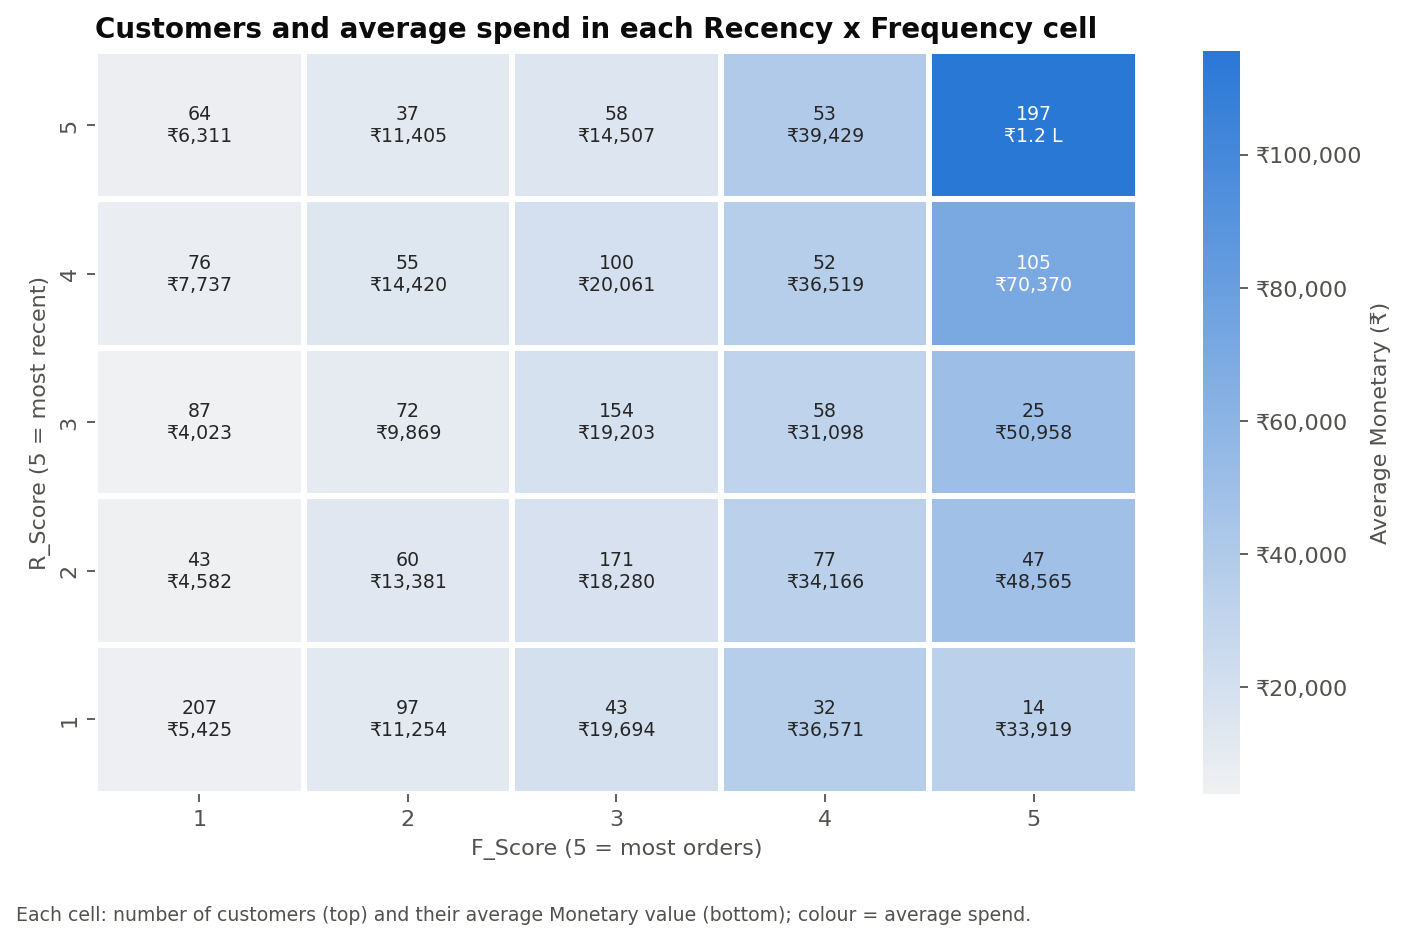

In [40]:
Image(str(FIG / "rfm_recency_frequency_heatmap.png"))

**Observation.**
- **Frequency and Monetary rise together** (ρ = 0.84). Champions sit at the top right of the Frequency-Monetary chart.
- Recency is only moderately related to the other two (ρ = −0.38 with F and −0.34 with M). A customer's past value says little about whether they are still active, which is exactly why "high value but lapsed" segments exist.
- The Recency-Frequency heatmap shows the highest average spend (₹1.2 L) in the most recent, most frequent cell. Customers with high Frequency but low recency (R = 1-2, F = 4-5) still average ₹33,900-₹48,600.

**Why no 3D chart.** A 3D R-F-M scatter was considered and left out on purpose. F and M are strongly correlated, so the third axis adds little that the two-dimensional views and the R × FM matrix do not already show. A rotating 3D plot is also hard to read in a report or presentation. The charts above use one facet per value-activity group instead of 11 colours, so every point stays distinguishable.

## 15. Business Insights
### 15.1 Customer behaviour questions (answers computed from data)

In [41]:
R['questions']

,Question,Answer (from data)
0,Q1. What percentage of customers are repeat customers?,"89.4% of scored customers (1,774) have 2+ delivered orders; 10.6% bought once."
1,Q2. What percentage of customers are highly active?,"28.9% are Champions or Loyal Customers (the 'Active high value' group, 574 customers); 42.5% bought in the last 90 days."
2,Q3. Which RFM segment contains the most customers?,Champions: 334 customers (16.8%).
3,Q4. Which segment contributes the most revenue?,Champions: ₹3.23 Cr (53.8% of revenue) from 16.8% of customers.
4,Q5. Which segment has the highest average monetary value?,"Champions: average ₹96,797 per customer vs ₹30,270 overall."
5,Q6. Which customers show high monetary value but poor recency?,"229 customers meet the rule M_Score >= 4 and R_Score <= 2; together ₹95.10 L (15.8% of revenue). Largest: CUST-0821 (₹1.20 L, 183 days), CUST-0760 (₹1.19 L,..."
6,Q7. How concentrated is revenue among high-value customers?,"Top 1% -> 9.0%, top 5% -> 30.0%, top 10% -> 45.5%, top 20% -> 64.3% (Gini 0.611). 80% of revenue needs 34.1% of customers, so it is concentrated but not an ..."
7,Q8. What proportion of customers appear inactive?,"'Inactive' group (Hibernating + Lost): 22.6% of customers, 4.5% of revenue. By recency alone, 34.9% have not bought for over 180 days."
8,Q9. Which segments should be investigated for retention strategies?,"Slipping segments ranked by revenue at stake: At Risk (263 customers, ₹67.63 L, avg recency 259 days); Can't Lose Them (79 customers, ₹42.85 L, avg recency ..."
9,Q10. Which customer groups should be analysed further with ML segmentation?,"(1) Champions (334 customers) - very wide spend range (₹19,923 to ₹4.18 L), so it may hide distinct sub-groups; (2) the Loyal Customers / At Risk pair (240 ..."


### 15.2 RFM insight table
Observation and Evidence are computed. Business Interpretation is a hypothesis for later steps to test.

In [42]:
R['insights']

,Insight Area,Observation,Evidence,Business Interpretation
0,Champions,About one customer in six generates over half of all revenue,"334 customers (16.8%) -> ₹3.23 Cr (53.8% of revenue); avg recency 33 days, avg 15.4 orders, avg spend ₹96,797",Protect with loyalty benefits and early access; losing even a few would hurt disproportionately
1,Loyal Customers,"Second value tier, slightly less recent","240 customers (12.1%) -> ₹85.79 L (14.3% of revenue); avg recency 91 days, avg 7.2 orders, avg spend ₹35,745",Upgrade path to Champions: cross-sell categories and reward frequency
2,Potential Loyalists,"Recent, mid-value buyers","152 customers (7.7%) -> ₹21.91 L (3.6% of revenue); avg recency 47 days, avg 4.2 orders, avg spend ₹14,418",Best growth pool: onboarding and second-category offers could move them up
3,At Risk / Can't Lose Them,Former high-value customers who have gone quiet,"At Risk: 263 customers (13.3%) -> ₹67.63 L (11.3% of revenue); avg recency 259 days, avg 5.9 orders, avg spend ₹25,717. Can't Lose Them: 79 customers (4.0%)...",Priority win-back targets: the revenue they used to generate is large
4,High-value at risk (rule),Top-40% spenders in the bottom-40% of recency,"229 customers, ₹95.10 L historical revenue (15.8%); median recency 226 days",A concrete Customer_ID list for a reactivation campaign (Step 7 CLV will size expected value)
5,Inactive customers,Hibernating + Lost are a large share of customers but little revenue,449 customers (22.6%) -> 4.5% of revenue,Low-cost automated reactivation only; do not spend premium retention budget here
6,Revenue Concentration,"Revenue is concentrated, but less than an 80/20 rule",Top 20% -> 64.3%; 80% of revenue comes from 34.1% of customers; Gini 0.611,A focused key-account style programme for the top fifth is justified
7,Repeat Customers,Almost all buyers come back at least once,Repeat (2+ orders): 89.4%; one-time: 10.6%,"Retention is working at a basic level; the lever is frequency and value, not first repeat"
8,Frequency vs Monetary,Frequency and Monetary move together,"Spearman rho(F, M) = 0.84","F and M carry overlapping information - one reason the segments use FM = (F+M)/2, and a point to handle (scaling / feature choice) in K-Means"
9,Recency,Recency separates recently active customers from a long-lapsed group,Median recency 121 days; 42.5% bought in the last 90 days; 34.9% not for 180+ days,"Recency is the earliest warning sign of a customer going quiet, and the one to monitor monthly - this project reports inactivity, never churn, because the d..."


## 16. RFM Summary
### 16.1 Data-science validation

In [43]:
R['validation']

,Check,Value,Pass
0,Each Customer_ID appears once in the RFM table,0,True
1,Scored + excluded customers = all customers,1984 + 16 = 2000 (of 2000),True
2,Frequency = distinct delivered Order_IDs (recomputed),match,True
3,Frequency differs from row count for multi-product orders,1290 customers have more lines than orders,True
4,Monetary total = delivered Sales total,₹6.01 Cr vs ₹6.01 Cr,True
5,Cancelled/Returned lines excluded from Monetary,₹62.55 L,True
6,Recency >= 0 for all customers,"min 1, max 1096",True
7,Reference date = max Order_Date + 1 day,2026-01-01,True
8,R/F/M scores are integers 1-5,all in {1..5},True
9,Tied values share one score,checked on Frequency and Monetary,True


In [44]:
assert R["validation"]["Pass"].all(), "A validation check failed"
seg_rev = R["segment_summary"]["Total_Revenue"].sum()
print(f"Segment revenue total: ₹{seg_rev:,.2f} | Customer Monetary total: ₹{seg['Monetary'].sum():,.2f} | "
      f"difference: ₹{abs(seg_rev - seg['Monetary'].sum()):.2f}")

Segment revenue total: ₹60,056,569.15 | Customer Monetary total: ₹60,056,569.15 | difference: ₹0.00


All 15 checks pass:
- Each customer appears once.
- Frequency equals distinct delivered orders.
- Monetary reconciles to delivered Sales (₹6.01 Cr).
- Recency is at least 1 for every customer.
- Scores are integers from 1 to 5, and tied values share a score.
- Every customer has exactly one segment.
- Segment revenue sums to total revenue (difference ₹0.00).

**Documented exception:** 16 customers with no delivered purchase were excluded from scoring on purpose (Section 3).

### 16.2 Summary
1. **1,984 customers were scored** against a derived reference date of 1 January 2026. Frequency counts distinct orders, and Monetary counts delivered revenue only.
2. **Champions (16.8% of customers) generate 53.8% of revenue.** Adding Loyal Customers, 28.9% of customers generate 68.1%.
3. **229 high-value customers are at risk.** They generated ₹95.10 L (15.8%) and have been inactive for a median of 226 days. They are the priority win-back list.
4. **Revenue is concentrated but not 80/20:** the top 20% generate 64.3%, and 80% of revenue needs 34.1% of customers.
5. **Nearly all buyers repeat** (89.4%), but 34.9% have not bought for more than 180 days. Recency, not first-time repeat, is the retention problem.
6. **F and M are strongly correlated (0.84)** and all three measures are right-skewed. Step 6 should use log-transformed, scaled inputs and account for this overlap.

**Handover to Step 6 (K-Means).** Use `data/processed/customer_rfm_segments.csv`, which has the RFM values, scores and rule-based segment labels. Log-transform and scale R, F and M, cluster the customers, then compare the clusters with these rule-based segments.

**Full methodology:** `outputs/reports/rfm_methodology.md`.